In [ ]:
import sympy as sp



# Wave-speed variables

rho, c11, c22, c33, c23, c13, c12, cs3, cs1, cs2 = sp.symbols(

    "rho c11 c22 c33 c23 c13 c12 cs3 cs1 cs2"

)
L1, L2, L3, Ls3, Ls1, Ls2, t11, t22, t33, t12, t23, t13, ts3, ts1, ts2, td = sp.symbols(
    "L_1 L_2 L_3 L_{s3} L_{s1} L_{s2} "
    "t_{11} t_{22} t_{33} t_{12} t_{23} t_{13} "
    "t_{s3} t_{s1} t_{s2} t_d"
)


# Independent stiffness coefficients: invert this compact symbolic matrix first

C11, C22, C33, C44, C55, C66, C12, C23, C13 = sp.symbols(

    "C11 C22 C33 C44 C55 C66 C12 C23 C13"

)

C_symbolic = sp.Matrix([

    [C11, C12, C13, 0, 0, 0],

    [C12, C22, C23, 0, 0, 0],

    [C13, C23, C33, 0, 0, 0],

    [0, 0, 0, C44, 0, 0],

    [0, 0, 0, 0, C55, 0],

    [0, 0, 0, 0, 0, C66],

])



S_symbolic = C_symbolic.inv()



# Substitute the physical definitions only after inversion

C_substitutions = {

    C11: rho*c11**2,

    C22: rho*c22**2,

    C33: rho*c33**2,

    C44: rho*c23**2,

    C55: rho*c13**2,

    C66: rho*c12**2,

}

C_substitutions.update({
     C12: sp.sqrt(
            (C_substitutions[C11] + C_substitutions[C66] - 2*rho*cs3**2) *
            (C_substitutions[C22] + C_substitutions[C66] - 2*rho*cs3**2)
        ) - C_substitutions[C66], # type: ignore
    
        C13: sp.sqrt(
            (C_substitutions[C11] + C_substitutions[C55] - 2*rho*cs1**2) *
            (C_substitutions[C33] + C_substitutions[C55] - 2*rho*cs1**2)
        ) - C_substitutions[C55], # type: ignore
    
        C23: sp.sqrt(
            (C_substitutions[C22] + C_substitutions[C44] - 2*rho*cs2**2) *
            (C_substitutions[C33] + C_substitutions[C44] - 2*rho*cs2**2)
        ) - C_substitutions[C44] # type: ignore
})
# nominal = {
#     c11: 2.18,
#     c12: 1.29,
#     c13: 1.28,
#     c22: 2.22,
#     c23: 1.26,
#     c33: 2.24,
#     cs3: 2.19,
#     cs1: 2.22,
#     cs2: 2.21,
#     rho: 1.19
# }

nominal={
    L1:24.66,
    L2:24.77,
    L3:24.78,
    Ls3:24.92,
    Ls1:25,
    Ls2:25.02,
    rho:1.19,
    td:0
}

nominal.update({
    t11:nominal[L1]/2.18,
    t22:nominal[L2]/2.22,
    t33:nominal[L3]/2.24,
    t12:nominal[L1]/1.29,
    t13:nominal[L1]/1.28,
    t23:nominal[L3]/1.26,
    ts3:nominal[Ls3]/2.19,
    ts1:nominal[Ls1]/2.22,
    ts2:nominal[Ls2]/2.21
})

velocities={
    c11: L1/(t11-td),
    c12: L1/(t12-td),
    c13: L1/(t13-td),
    c22: L2/(t22-td),
    c23: L2/(t23-td),
    c33: L3/(t33-td),
    cs3: Ls3/(ts3-td),
    cs1: Ls1/(ts1-td),
    cs2: Ls2/(ts2-td),
}

S_mat=S_symbolic.subs(C_substitutions).subs(velocities)
print(S_mat[0,0].free_symbols)
E_indices=[0,1,2]

# variables=[
#     L1, L2, L3, Ls3, Ls1, Ls2, t11, t22, t33, t12, t23, t13, ts3, ts1, ts2, td
# ]
sensitivities={}

for index in E_indices:
    variables=S_mat[index,index].free_symbols
    E=1/S_mat[index,index]
    print(f"Nominal E{index+1}: {E.subs(nominal)}")

    if f"E{index+1}" not in sensitivities.keys():
        sensitivities[f"E{index+1}"]={}
    for x in variables:
        
        
        # Analytical derivative
        dE_dx = sp.diff(E, x)

        # Evaluate derivative at nominal values
        sensitivity = float(dE_dx.subs(nominal))

        print(
            f"dE{index+1}/d{x} = {sensitivity:.6g}"
        )
        sensitivities[f"E{index+1}"][x]=sensitivity



In [82]:
import numpy as np

def get_center_band_of_ones(main_array:np.ndarray)->tuple[int,int]:

    array2=array.copy()
    global_start=0
    global_end=0

    while sum(array2)!=(len(array2)):

        g_1=np.where(array2>1)[0]

        start=g_1[0]
        end=g_1[-1]


        if start==end:
            if sum(array2[0:end])==len(array2[0:end]):
                global_end+=(end-len(array2))

            elif sum(array2[start:-1])==len(array2[start:-1]):
                global_start+=start+1

        else:
            global_start+=start+1
            global_end+=(end-len(array2))


        array2=array[global_start:global_end]

    return global_start,global_end

array=[0,1,2,3,5,6,8,9,10]

4
39
5
-2
[4 5 1 1 1 1 1 1 1 1 3 4 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
0
11
6
-25
[5 1 1 1 1 1 1 1 1 3]
0
9
7
-26
[1 1 1 1 1 1 1 1]


Data acquired for 1
22.245509721633336


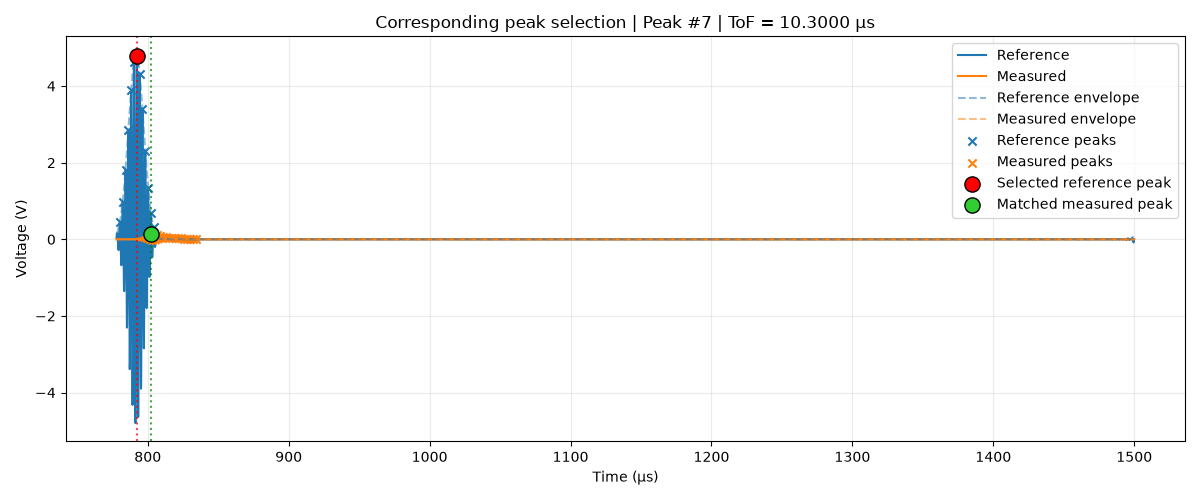

Tof: 1.0300000000000088e-05
Attenuation: 1603.656962580938
Velocity: 2470.3703703703604


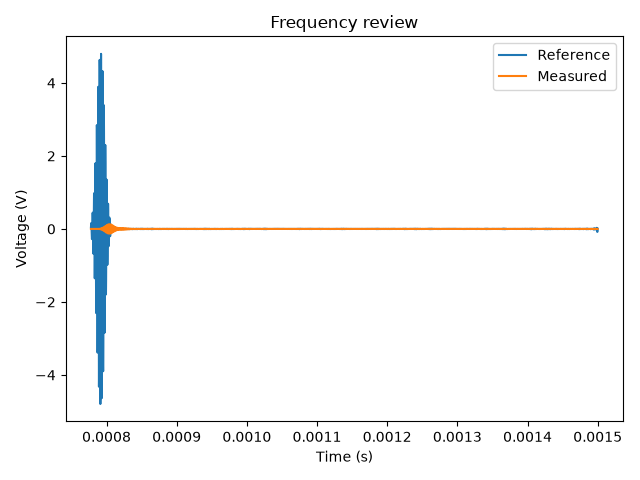

In [43]:


# Review frequency content
%matplotlib widget

import pandas as pd
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
from typing import Literal


def get_corresponding_peaks(
    time: np.ndarray,
    reference: np.ndarray,
    measured: np.ndarray,
    envelope_threshold: float = 0.05,
    min_peak_prominence: float = 0.0,
    plot: bool = True,
) -> tuple[float, int, int]:
    """
    Match positive peaks by their ordinal position within each pulse.

    The largest positive reference peak determines the peak number.
    The corresponding peak number is selected in the measured pulse.

    Returns:
        tof: Time of flight in seconds
        ref_idx: Selected reference peak index
        measured_idx: Selected measured peak index
    """

    time = np.asarray(time)
    reference = np.asarray(reference)
    measured = np.asarray(measured)

    if not (len(time) == len(reference) == len(measured)):
        raise ValueError("Time and signal arrays must have equal lengths.")

    # Calculate Hilbert envelopes.
    ref_envelope = np.abs(signal.hilbert(reference))
    measured_envelope = np.abs(signal.hilbert(measured))

    def get_pulse_bounds(envelope):
        """Find the contiguous threshold region containing the envelope maximum."""
        peak_idx = int(np.argmax(envelope))
        threshold = envelope_threshold * envelope[peak_idx]

        start = peak_idx
        while start > 0 and envelope[start - 1] >= threshold:
            start -= 1

        end = peak_idx + 1
        while end < len(envelope) and envelope[end] >= threshold:
            end += 1

        return start, end

    ref_start, ref_end = get_pulse_bounds(ref_envelope)
    measured_start, measured_end = get_pulse_bounds(measured_envelope)

    # Find positive local maxima within each envelope.
    ref_peaks, _ = signal.find_peaks(
        reference[ref_start:ref_end],
        prominence=min_peak_prominence
    )

    measured_peaks, _ = signal.find_peaks(
        measured[measured_start:measured_end],
        prominence=min_peak_prominence
    )

    # Convert indices back to the original arrays.
    ref_peaks += ref_start
    measured_peaks += measured_start

    if len(ref_peaks) == 0 or len(measured_peaks) == 0:
        raise ValueError("No positive peaks found inside one of the pulses.")

    # Retain positive-amplitude peaks only.
    ref_peaks = ref_peaks[reference[ref_peaks] > 0]
    measured_peaks = measured_peaks[measured[measured_peaks] > 0]

    if len(ref_peaks) == 0 or len(measured_peaks) == 0:
        raise ValueError("No positive-amplitude peaks detected.")

    # Select the largest positive peak of the reference signal.
    ref_peak_number = int(np.argmax(reference[ref_peaks]))
    ref_idx = int(ref_peaks[ref_peak_number])

    # Match the same ordinal peak in the measured signal.
    if ref_peak_number >= len(measured_peaks):
        raise ValueError(
            f"Reference peak number {ref_peak_number + 1} "
            f"cannot be matched: measured pulse has only "
            f"{len(measured_peaks)} positive peaks."
        )

    measured_idx = int(measured_peaks[ref_peak_number])

    tof = float(time[measured_idx] - time[ref_idx])

    if tof <= 0:
        raise ValueError("Selected measured peak occurs before reference peak.")

    if plot:
        fig, ax = plt.subplots(figsize=(12, 5))

        ax.plot(time * 1e6, reference, label="Reference", color="C0")
        ax.plot(time * 1e6, measured, label="Measured", color="C1")

        ax.plot(
            time * 1e6, ref_envelope,
            "--", color="C0", alpha=0.5,
            label="Reference envelope"
        )
        ax.plot(
            time * 1e6, measured_envelope,
            "--", color="C1", alpha=0.5,
            label="Measured envelope"
        )

        # Display all detected positive peaks.
        ax.scatter(
            time[ref_peaks] * 1e6,
            reference[ref_peaks],
            color="C0", marker="x", s=35,
            label="Reference peaks"
        )
        ax.scatter(
            time[measured_peaks] * 1e6,
            measured[measured_peaks],
            color="C1", marker="x", s=35,
            label="Measured peaks"
        )

        # Highlight matched peaks.
        ax.scatter(
            time[ref_idx] * 1e6,
            reference[ref_idx],
            color="red", edgecolors="black",
            s=120, zorder=5,
            label="Selected reference peak"
        )
        ax.scatter(
            time[measured_idx] * 1e6,
            measured[measured_idx],
            color="limegreen", edgecolors="black",
            s=120, zorder=5,
            label="Matched measured peak"
        )

        ax.axvline(time[ref_idx] * 1e6, color="red", linestyle=":", alpha=0.7)
        ax.axvline(time[measured_idx] * 1e6, color="green", linestyle=":", alpha=0.7)

        ax.set_title(
            f"Corresponding peak selection | "
            f"Peak #{ref_peak_number + 1} | ToF = {tof * 1e6:.4f} µs"
        )
        ax.set_xlabel("Time (µs)")
        ax.set_ylabel("Voltage (V)")
        ax.grid(alpha=0.25)
        ax.legend(loc="best")
        fig.tight_layout()
        plt.show()

    return tof, ref_idx, measured_idx

def get_max_band(array:np.ndarray,percentage:float)->tuple[int,int]:

    cuttoff_value=np.max(array)*percentage
    max_idx=np.argmax(array)

    idxs_greater_than_cutoff=np.where(array>cuttoff_value)[0]
    difference_between_idxs=np.diff(idxs_greater_than_cutoff)

    is_one = difference_between_idxs == 1

    # False boundaries ensure runs touching either edge are detected.
    changes = np.diff(np.concatenate(([False], is_one, [False])).astype(int))


    starts = np.flatnonzero(changes == 1)
    ends = np.flatnonzero(changes == -1)

    global_start=0
    global_end=0

    for start, end in zip(starts, ends):
        band_start = idxs_greater_than_cutoff[start]
        band_end = idxs_greater_than_cutoff[end]
    
        if band_start <= max_idx <= band_end:
            global_start = int(band_start)
            global_end = int(band_end)
    
            break

    return global_start, global_end
       
def get_frequency_spectra_range(time:np.ndarray,y:np.ndarray,cutoff_percentage:float,cutoff_expander:int,min_cutoff_frequency:float=0.00)->tuple[float,float,float]:
    """
    Gets the min and max effective frequency range of a broadband pulse

    time: Time values (numpy array expected)
    y: Corresponding values for the time series (numpy array expected)
    cutoff_percentage: This perecntage of the maximum amplitude of the signal will determine the cutoff frequencies, anything below it will be treated as noise and removed.
    cutoff_expander: This integer value will expand the tip and tail of the band by increasing the width of the band
    min_cutoff_frequency: Initial cutoff to remove noise that is present at for example 0Hz (steady state noise) 

    Returns:
    Tuple[min_cutoff, max_cutoff, sample_spacing]

    Note: This will only work for a broadband pulse with one continious range, if seperate ranges are contained within the signal it will fail
    """
    # Assumes time_s is in seconds and samples are uniformly spaced
    sample_spacing = np.median(np.diff(time))

    # Convert time domain -> frequency domain
    spectrum = np.fft.rfft(y)
    frequencies = np.fft.rfftfreq(len(y), d=sample_spacing)

    # Band-pass limits in Hz
    low_cutoff_hz = min_cutoff_frequency

    # Keep only frequencies inside the pass band
    passband = (
        (frequencies > low_cutoff_hz)
    )

    filtered_spectrum = spectrum.copy()
    filtered_spectrum[~passband] = 0
    
    min_cutoff_idx,_=get_max_band(np.abs(filtered_spectrum),0.01)
    max_idx=np.argmax(np.abs(filtered_spectrum))

    max_cutoff_idx=max_idx+(max_idx-min_cutoff_idx)
    min_cutoff = frequencies[min_cutoff_idx]
    max_cutoff = frequencies[max_cutoff_idx]

    return min_cutoff, max_cutoff, sample_spacing


def band_pass_filter(y:np.ndarray,low_pass_frequency:float, high_pass_frequency:float, sample_spacing:float)->np.ndarray: 
     # Convert time domain -> frequency domain
    spectrum = np.fft.rfft(y)
    frequencies = np.fft.rfftfreq(len(y), d=sample_spacing)

    
    inside_band = (
        (frequencies >= low_pass_frequency)
        & (frequencies <= high_pass_frequency)
    )

    

    spectrum[~inside_band] = 0

    filtered_signal= np.fft.irfft(
        spectrum,
        n=len(y)
    )

    return filtered_signal


def get_gain_factor(solve_for:Literal["in","out"],db_gain:float)->float:

    if solve_for=="out":
        return 10**(db_gain/20)

    else :
        return 1/(10**(db_gain/20))



def get_ultrasonic_characteristics(
    time: np.ndarray,
    y1: np.ndarray,
    y2: np.ndarray,
    f_min: float,
    f_max: float,
    sample_spacing: float,
    envelope_threshold: float = 0.05,
    plot_peaks: bool = True,
) -> tuple[float, float]:

    # Calculate ToF using corresponding positive peaks.
    tof, ref_idx, measured_idx = get_corresponding_peaks(
        time,
        y1,
        y2,
        envelope_threshold=envelope_threshold,
        plot=plot_peaks
    )

    # Existing frequency-domain amplitude calculation.
    spectrum_y1 = np.fft.rfft(y1)
    spectrum_y2 = np.fft.rfft(y2)

    frequencies = np.fft.rfftfreq(len(y1), d=sample_spacing)

    frequency_indices = np.where(
        (frequencies >= f_min) &
        (frequencies <= f_max)
    )[0]

    if len(frequency_indices) == 0:
        raise ValueError("No FFT bins within selected frequency range.")

    filtered_spectra_y1 = np.abs(spectrum_y1[frequency_indices])
    filtered_spectra_y2 = np.abs(spectrum_y2[frequency_indices])

    max_idx = np.argmax(filtered_spectra_y1)

    attenuation = -20 * np.log10(
        filtered_spectra_y2[max_idx] /
        filtered_spectra_y1[max_idx]
    )

    return float(tof), float(attenuation)


def review_ultrasonic_signals(
    time: np.ndarray,
    reference: np.ndarray,
    measured: np.ndarray,
    cutoff_percentage: float = 0.05,
    cutoff_expander: int = 10,
    min_cutoff_frequency: float = 0.0,
) -> tuple[float,float]:
    """
    Show signal and attenuation plots; return peak-to-peak ToF in seconds and attenuation at center of broadband pulse and SNR

    Pass uniformly spaced time values in seconds and matching voltage arrays.
    Each call creates new inline figures, so loop iterations keep their plots.
    """
    # Get pulse starts
    hilbert_ref = np.abs(signal.hilbert(reference))#type: ignore
    hilbert_measured = np.abs(signal.hilbert(measured)) #type: ignore
    
    ref_start,_=get_max_band(hilbert_ref,cutoff_percentage)
    measured_start,_=get_max_band(hilbert_measured,cutoff_percentage)

    ref_start=ref_start-10
    measured_start=measured_start-10

    reference_dist=np.argmax(reference)-ref_start

    measured_dist=np.argmax(measured)-measured_start

    # Slice everything to start at ref start
    time=time[ref_start:]
    reference=reference[ref_start:]
    measured=measured[ref_start:]

    # Reset start idxs, start with measured before resetting ref to 0, everything shifts left on time axis
    measured_start=measured_start-ref_start
    ref_start=0

    ref_end=reference_dist
    measured_end = measured_start+measured_dist

    

    minimum_frequency, max_frequency, spacing = get_frequency_spectra_range(
        time, reference, cutoff_percentage, cutoff_expander, min_cutoff_frequency
    )

    outside_pulse_measured = np.concat([measured[0:measured_start],measured[measured_end:-1]])

    N_rms=np.sqrt(np.mean(np.square(outside_pulse_measured)))

    Measured_Pulse_Amplitude = (np.max(measured)-np.min(measured))/2

    SNR=20*np.log10(Measured_Pulse_Amplitude/N_rms)
    print(SNR)

    filtered_reference = band_pass_filter(reference, minimum_frequency, max_frequency, spacing)
    filtered_measured = band_pass_filter(measured, minimum_frequency, max_frequency, spacing)
    tof, attenuation = get_ultrasonic_characteristics(
        time, filtered_reference, filtered_measured, minimum_frequency, max_frequency, spacing
    )

    fig, ax = plt.subplots()
    ax.set_title("Frequency review")
    ax.plot(time, filtered_reference, label="Reference")
    ax.plot(time, filtered_measured, label="Measured")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Voltage (V)")
    ax.legend()
    fig.tight_layout()

    return float(tof), float(attenuation)

L=20.01 *10**(-3)#
Tofs=[]
# for i in range(10):
    # if i+1==4 or i+1==10:
    #     continue
print(f"Data acquired for {1}")
data = pd.read_csv(f"data/{1}.csv")

data = data.set_index("time_s")
ToF,attenuation = review_ultrasonic_signals(
    data.index.to_numpy(), data["reference_v"].to_numpy(), data["measured_v"].to_numpy()
)
print(f"Tof: {ToF}")
print(f"Attenuation: {attenuation/L}")
print(f"Velocity: {L/(ToF-2.2000000000000535e-06)}")

Temporal resolution 1.4884279200460837e-09
Sampling frequency 671849799.7330221
[  25   30   33   41   46   49   58   62   66   68   73   76   80   83
   86   92   94   96  102  104  107  110  114  121  126  130  132  135
  142  149  156  160  165  168  174  178  181  183  186  194  196  201
  203  206  208  211  213  216  223  225  227  229  235  239  250  253
  257  260  263  265  268  271  277  279  281  284  288  291  294  300
  302  306  308  316  319  322  324  326  336  339  348  354  360  371
  375  380  383  387  392  399  402  405  411  414  417  421  425  432
  435  441  445  447  451  466  490  514  518  522  527  535  549  560
  563  565  639  655  719  748  808  868  925 1100 1189 1211 1281 1437
 1512 1532 1792 1991 3471 3610 3661 3723 3941 4004 4066 4502 4687 4713
 4751 4756 4785 4797 4850 4853 4860 4863 4875 4907 4929 4951 4964 5037
 5039 5045 5057 5066 5068 5072 5077 5079 5091 5093 5102 5107 5109 5115
 5118 5122 5130 5139 5146 5149 5151 5154 5158 5166 5173 5181 5185 51

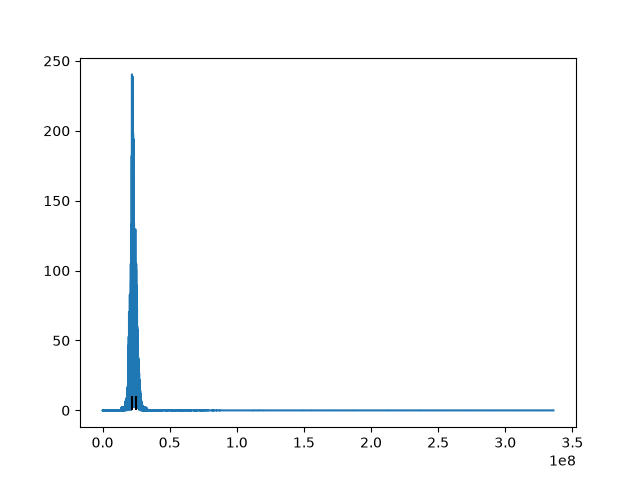

In [4]:
%matplotlib widget

import numpy as np
import pandas as pd
from scipy import signal
import matplotlib.pyplot as plt
def get_max_band(array:np.ndarray,percentage:float)->tuple[int,int]:

    cuttoff_value=np.max(array)*percentage
    max_idx=np.argmax(array)

    idxs_greater_than_cutoff=np.where(array>cuttoff_value)[0]
    difference_between_idxs=np.diff(idxs_greater_than_cutoff)

    is_one = difference_between_idxs == 1

    # False boundaries ensure runs touching either edge are detected.
    changes = np.diff(np.concatenate(([False], is_one, [False])).astype(int))


    starts = np.flatnonzero(changes == 1)
    ends = np.flatnonzero(changes == -1)

    print(starts)
    print(ends)
    print(max_idx)
    global_start=0
    global_end=0

    for start, end in zip(starts, ends):
        band_start = idxs_greater_than_cutoff[start]
        band_end = idxs_greater_than_cutoff[end]
    
        if band_start <= max_idx <= band_end:
            global_start = int(band_start)
            global_end = int(band_end)
            print("Condition satisfied",band_start, band_end)
            break

    print("Global start",global_start)
    return global_start, global_end

data = pd.read_csv(f"data/data_sample_waveforms.csv")
    
data = data.set_index("time_s")

measured=data["filtered_measured_v"].to_numpy()

sample_spacing=np.mean(np.diff(data.index))
print("Temporal resolution",sample_spacing)
print("Sampling frequency",1/sample_spacing)
spectrum = np.abs(np.fft.rfft(measured))
frequencies = np.fft.rfftfreq(len(measured), d=sample_spacing)
filtered_mask= (frequencies>0)

spectrum[~filtered_mask]=0

min_cutoff_idx,max_cutoff_idx=get_max_band(np.abs(spectrum),0.01)

fig3=plt.figure(num="1",clear=True)
ax3=fig3.subplots()
ax3.plot(frequencies,spectrum)
ax3.vlines(frequencies[min_cutoff_idx],0,10,colors="black")
ax3.vlines(frequencies[max_cutoff_idx],0,10,colors="black")
plt.show()

In [134]:
print(Tofs)

[1.2300000000000028e-05, 1.2300000000000028e-05, 1.2399999999999976e-05, 1.2300000000000028e-05, 1.2300000000000028e-05, 1.2300000000000028e-05, 1.229999999999992e-05, 1.2300000000000028e-05]


In [230]:
%matplotlib widget
from scipy import signal

def analyze_windowed_pulses(data: pd.DataFrame, alpha: float = 0.5) -> tuple[float, float]:
    """Plot isolated Tukey-windowed pulses and return (peak ToF, envelope ToF) in seconds.

    Input columns: time_s, reference_v, measured_v. Keep the second half, crop
    both channels at the raw reference envelope's 0.5% start, and reset time.
    Filter using the reference band, then mirror each filtered envelope start
    about its maximum to isolate the pulse. Taper before FFT, not before ToF.
    Alpha is the total tapered fraction (0 = rectangular, 1 = Hann).
    Requires get_frequency_spectra_range and band_pass_filter from the cell above.
    """
    if not np.isfinite(alpha) or not 0 <= alpha <= 1:
        raise ValueError("alpha must be between 0 and 1.")
    samples = data.loc[:, ["time_s", "reference_v", "measured_v"]].iloc[len(data) // 2:].copy()
    values = samples.to_numpy(dtype=float)
    if len(values) < 3 or not np.isfinite(values).all():
        raise ValueError("The retained data must contain at least three finite samples.")
    steps = np.diff(values[:, 0])
    if np.any(steps <= 0) or not np.allclose(steps, np.median(steps), rtol=1e-4, atol=0):
        raise ValueError("time_s must be increasing and uniformly spaced.")

    def envelope_start(envelope: np.ndarray) -> int:
        peak = int(np.argmax(envelope))
        if envelope[peak] <= 0:
            raise ValueError("Cannot detect a pulse in a zero signal.")
        below = np.flatnonzero(envelope[:peak] <= 0.005 * envelope[peak])
        return int(below[-1] + 1) if below.size else 0

    crop_start = envelope_start(np.abs(signal.hilbert(values[:, 1])))
    values = values[crop_start:]
    if len(values) < 3:
        raise ValueError("Too few samples remain after cropping at the reference start.")
    time = values[:, 0] - values[0, 0]
    reference, measured = values[:, 1], values[:, 2]
    f_min, f_max, spacing = get_frequency_spectra_range(time, reference, 0.005, 10, 0)
    cleaned_ref = band_pass_filter(reference, f_min, f_max, spacing)
    cleaned_measured = band_pass_filter(measured, f_min, f_max, spacing)
    hilbert_ref = np.abs(signal.hilbert(cleaned_ref))
    hilbert_measured = np.abs(signal.hilbert(cleaned_measured))

    def isolate_pulse(y: np.ndarray, envelope: np.ndarray) -> tuple[np.ndarray, int, int, int]:
        start = envelope_start(envelope)
        end = 2 * int(np.argmax(envelope)) - start
        if end >= len(y) or end - start < 2:
            raise ValueError("The symmetric pulse must fit in the recording and span at least three samples.")
        pulse = y[start:end + 1]
        peak = start + int(np.argmax(pulse))
        windowed = np.zeros_like(y)
        windowed[start:end + 1] = pulse * signal.windows.tukey(len(pulse), alpha=alpha)
        return windowed, start, end, peak

    windowed_ref, ref_start, ref_end, ref_peak = isolate_pulse(cleaned_ref, hilbert_ref)
    windowed_measured, measured_start, measured_end, measured_peak = isolate_pulse(cleaned_measured, hilbert_measured)
    peak_tof = float(time[measured_peak] - time[ref_peak])
    envelope_tof = float(time[np.argmax(hilbert_measured)] - time[np.argmax(hilbert_ref)])
    if peak_tof < 0 or envelope_tof < 0:
        raise ValueError("The measured pulse precedes the reference pulse.")

    fig, ax = plt.subplots()
    ax.set_title(f"Isolated pulses (Tukey alpha={alpha:g})")
    ax.plot(time, cleaned_ref, label="Ref before taper", color="blue", alpha=0.3)
    ax.plot(time, cleaned_measured, label="Measured before taper", color="red", alpha=0.3)
    ax.plot(time, windowed_ref, label="Windowed ref", color="blue")
    ax.plot(time, windowed_measured, label="Windowed measured", color="red")
    ax.plot(time, hilbert_ref, label="Ref envelope", color="orange")
    ax.plot(time, hilbert_measured, label="Measured envelope", color="green")
    for index in (ref_start, ref_end):
        ax.axvline(time[index], color="black", linestyle="--")
    for index in (measured_start, measured_end):
        ax.axvline(time[index], color="gray", linestyle="--")
    ax.scatter([time[ref_peak], time[measured_peak]], [cleaned_ref[ref_peak], cleaned_measured[measured_peak]], color="black")
    ax.set_xlabel("Time since reference start (s)")
    ax.set_ylabel("Voltage (V)")
    ax.legend()
    fig.tight_layout()

    frequencies = np.fft.rfftfreq(len(time), d=spacing)
    fig2, ax2 = plt.subplots()
    ax2.set_title("Windowed pulse spectra")
    ax2.plot(frequencies, np.abs(np.fft.rfft(windowed_measured)), label="Measured")
    ax2.plot(frequencies, np.abs(np.fft.rfft(windowed_ref)), label="Reference")
    ax2.set_xlabel("Frequency (Hz)")
    ax2.set_ylabel("FFT magnitude (unnormalized)")
    ax2.legend()
    fig2.tight_layout()
    plt.show()
    return peak_tof, envelope_tof

data = pd.read_csv("data/Test 2/2.csv")
delta_t1, delta_t2 = analyze_windowed_pulses(data, alpha=0.05)
print(f"Peak ToF: {delta_t1:.6g} s; envelope ToF: {delta_t2:.6g} s")

[   0  964 1636 1901 2395 2817 3058]
[ 963 1635 1900 2394 2816 3057 3743]
3512
Condition satisfied 3065 3750
Global start 3065


IndexError: index 3959 is out of bounds for axis 0 with size 3751

sample_spacing 6.666666666670444e-08
Sampling Frequency 14999999.9999915
(335477,)
(335478,)


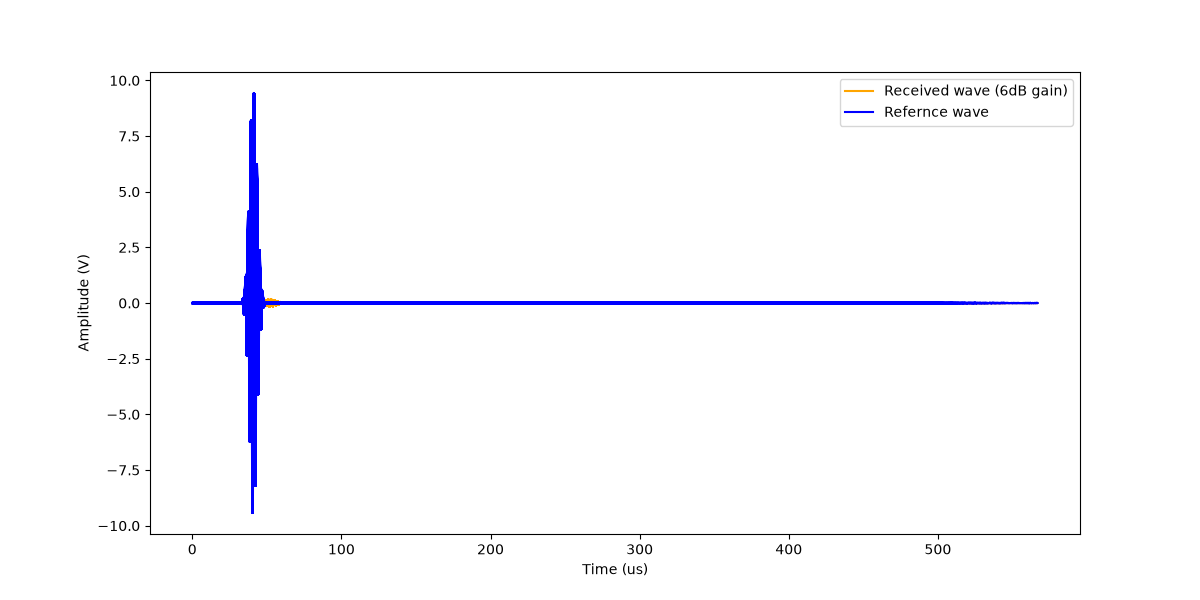

In [9]:
import pandas as pd
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt


data=pd.read_csv("data/data_sample_waveforms.csv")

# print("Data acquired")
# data = data.iloc[len(data) // 2:].reset_index(drop=True)
data=data.set_index("time_s")
# Use label-based selection on the time_s index, not positional .iloc

reference = data["filtered_reference_v"].to_numpy()
measured = data["filtered_measured_v"].to_numpy()
sample_spacing = data.index[1] - data.index[0]

print("sample_spacing",sample_spacing)
print("Sampling Frequency",1/sample_spacing)
spectrum = np.fft.rfft(reference)
frequencies = np.fft.rfftfreq(len(reference), d=sample_spacing)
amplitude = np.abs(spectrum) / len(reference)
amplitude[1:-1] *= 2

gain_db=6
min_ts=data.index.min()
reference_gain = 10 ** (gain_db / 20)
envelope_r=np.abs(signal.hilbert(reference))
envelope_m=np.abs(signal.hilbert(measured))

envelope_r_dV_dt=np.diff(envelope_r)/np.diff(data.index)

scaling_factor=reference.max()/envelope_r_dV_dt.max()

print(envelope_r_dV_dt.shape)
print(data.index.shape)
# After set_index("time_s"), the time is the index, not a column
plt.figure(figsize=(12,6))

plt.plot((data.index-min_ts)*1e6, measured,"orange",label="Received wave (6dB gain)")
# plt.plot((data.index-min_ts), envelope_m, color="orange", linestyle="--")
plt.plot((data.index-min_ts)*1e6, reference*reference_gain,"blue",label="Refernce wave")
# plt.plot((data.index - min_ts) * 1e6, np.concat([[0], envelope_r_dV_dt * scaling_factor]), "red", label="Scaled d(envelope)/dt")
plt.xlabel("Time (us)")
plt.ylabel("Amplitude (V)")
plt.legend()
plt.plot((data.index - min_ts) * 1e6, envelope_r,"blue",linestyle="--")


In [5]:
# pip install scipy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import pandas as pd

data=pd.read_csv("data/Test/Test.csv")
data = data.iloc[len(data) // 1:].reset_index(drop=True)
data=data.set_index("time_s")
# Use label-based selection on the time_s index, not positional .iloc
# data = data.loc[0.00085:(0.00085+80e-6)].copy()


gain_db=6

reference_gain = 10 ** (gain_db / 20)
envelope_r=np.abs(signal.hilbert(data["reference_v"]))
envelope_m=np.abs(signal.hilbert(data["measured_v"]))
# After set_index("time_s"), the time is the index, not a column
plt.figure(figsize=(12,6))
plt.plot((data.index-0)*1e6, data["measured_v"],"orange",label="Received wave (6dB gain)")
plt.plot((data.index-0)*1e6, envelope_m, color="red", linestyle="--",label="Envelope")
plt.plot((data.index-0)*1e6, data["reference_v"],"blue",label="Refernce wave")
plt.xlabel("Time (us)")
plt.ylabel("Amplitude (V)")
plt.legend()
# plt.plot(data.index, envelope_r,"blue",linestyle="--")


ValueError: N must be positive.

In [3]:
import sympy as sp

L,t,delta_t=sp.symbols("L t delta_t")

v=L/(t-delta_t)

dvdL=sp.diff(v,L)

dvdt=sp.diff(v,t)

dvddt=sp.diff(v,delta_t)

print("L: ",dvdL)
print("t: ",dvdt)
print("delta_t: ",dvddt)

L:  1/(-delta_t + t)
t:  -L/(-delta_t + t)**2
delta_t:  L/(-delta_t + t)**2


Measurement 1: Gain = 4.493 dB at 0.503 MHz
Measurement 2: Gain = 5.139 dB at 0.496 MHz
Measurement 3: Gain = 5.071 dB at 0.500 MHz
Measurement 4: Gain = 5.086 dB at 0.496 MHz
Measurement 5: Gain = 4.891 dB at 0.500 MHz
Measurement 6: Gain = 5.217 dB at 0.500 MHz
Measurement 7: Gain = 4.918 dB at 0.501 MHz
Measurement 8: Gain = 5.142 dB at 0.503 MHz
Measurement 9: Gain = 4.589 dB at 0.494 MHz
Measurement 10: Gain = 5.348 dB at 0.498 MHz

Amplifier gain summary:
 Measurement  Frequency (MHz)  Gain (dB)
           1         0.503000   4.493455
           2         0.495667   5.139282
           3         0.500333   5.070521
           4         0.495667   5.086096
           5         0.499667   4.890717
           6         0.500000   5.217410
           7         0.501000   4.917598
           8         0.503333   5.141625
           9         0.494333   4.589177
          10         0.498000   5.348474

Mean gain: 4.98943560 dB
Standard deviation: 0.27152320 dB


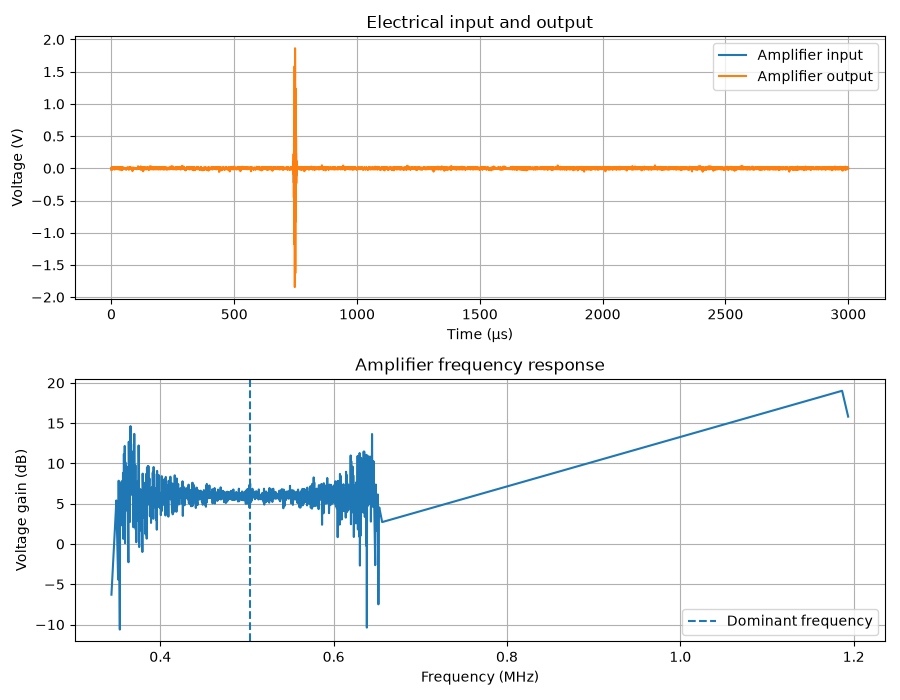

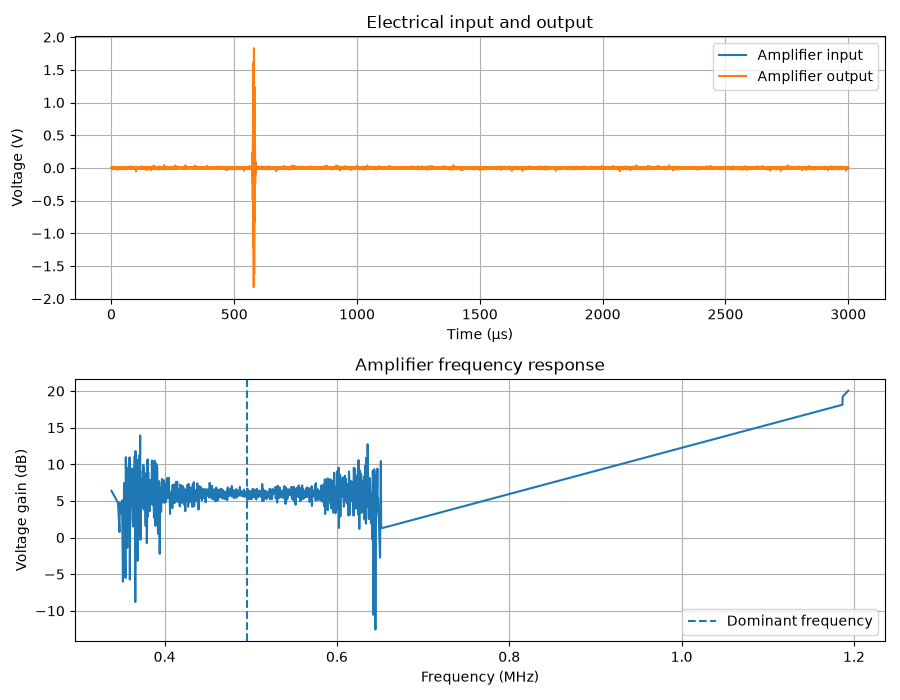

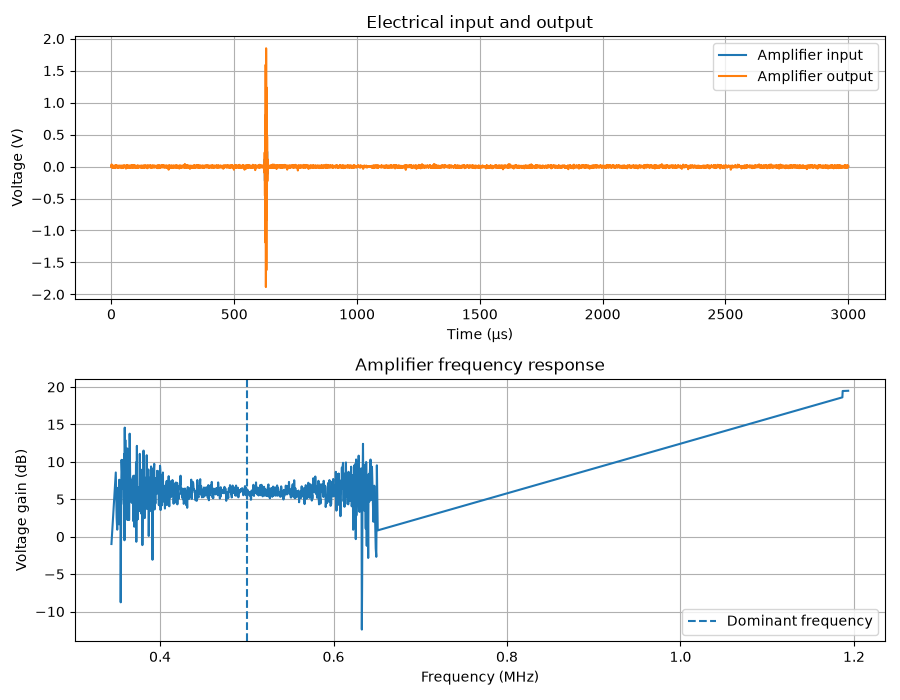

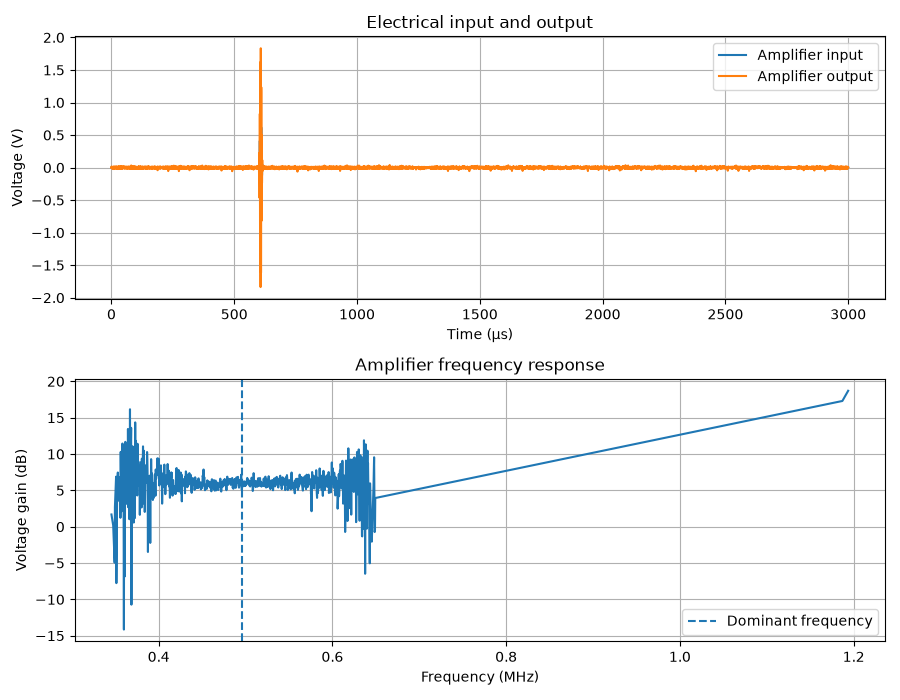

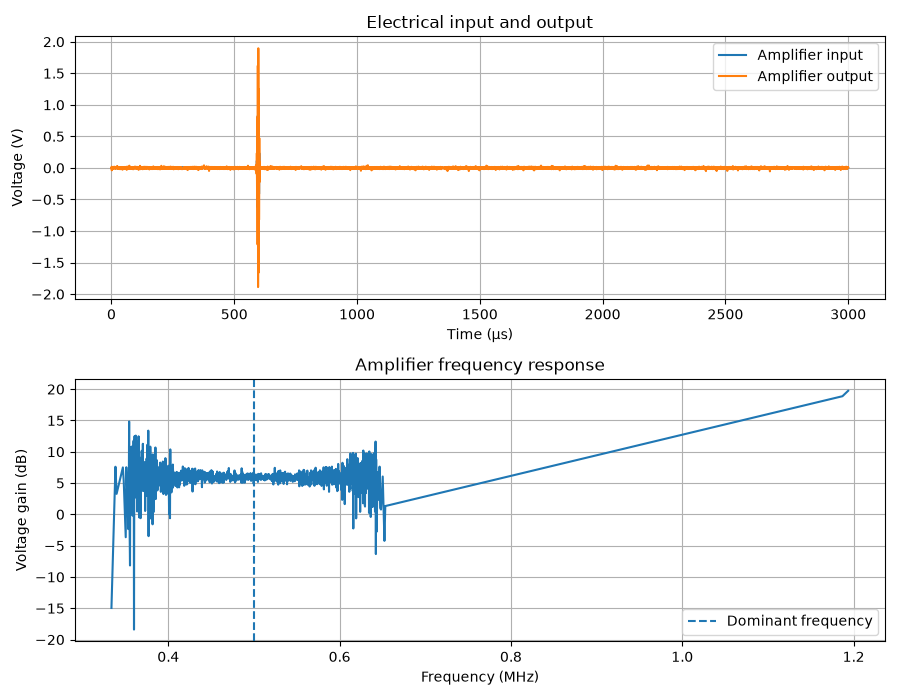

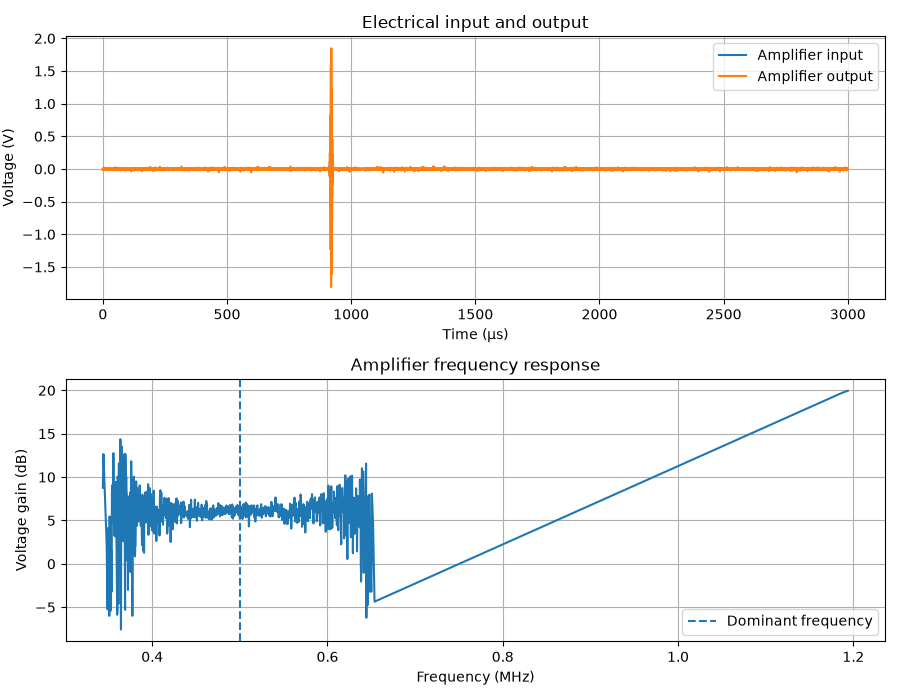

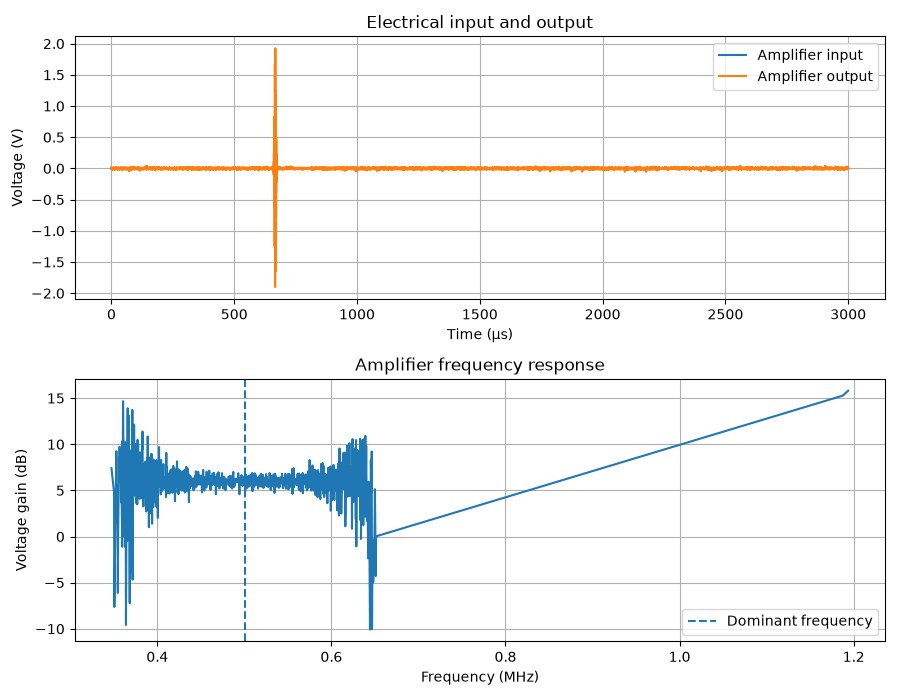

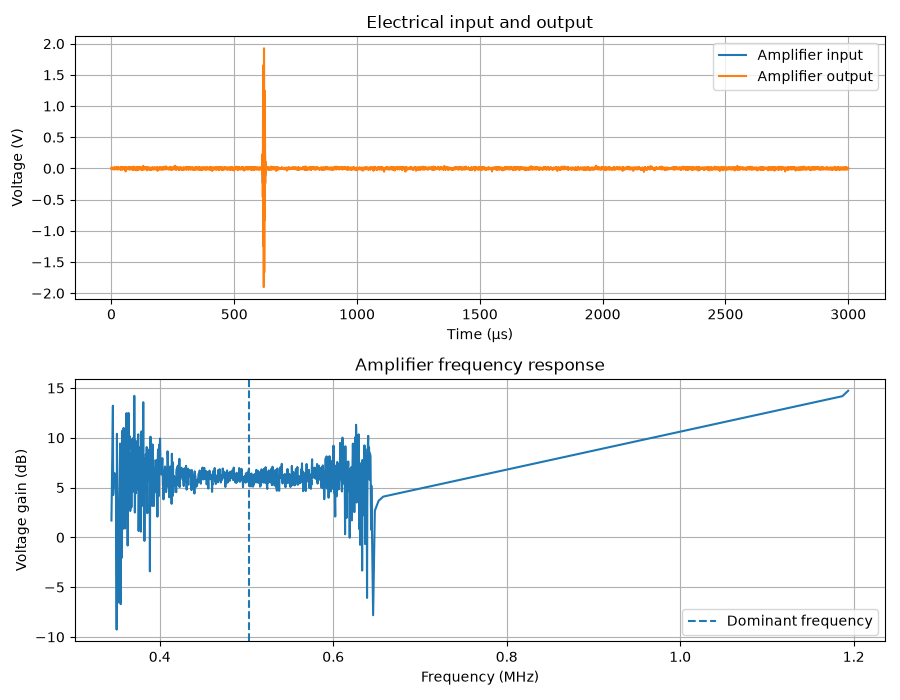

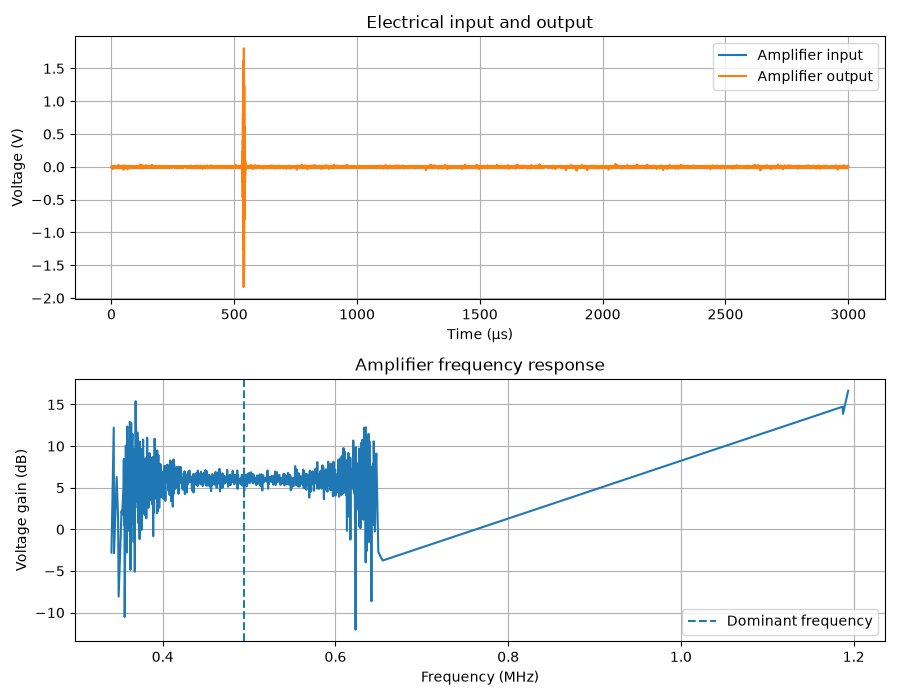

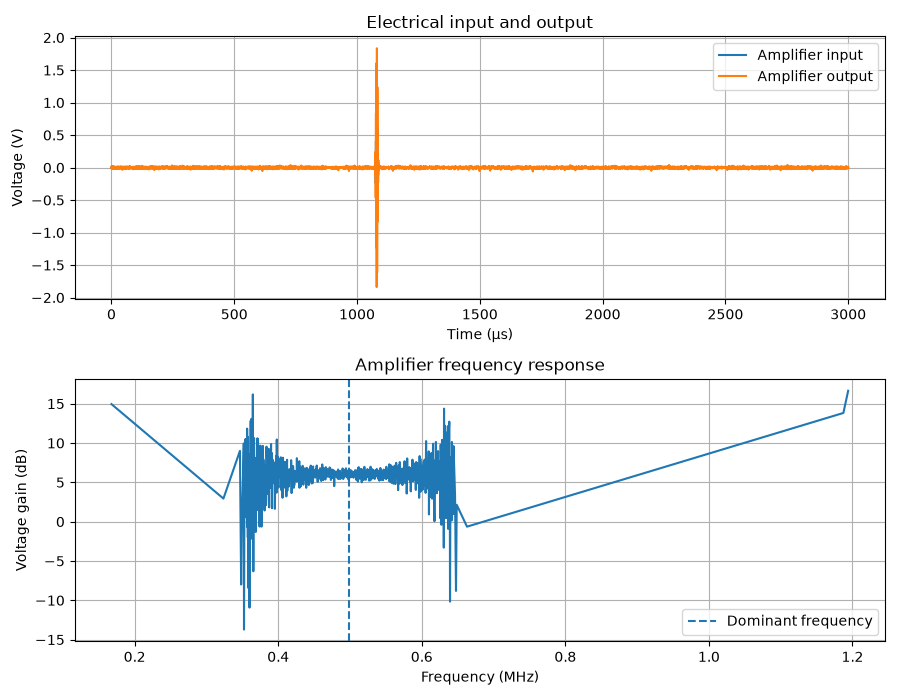

In [13]:

%matplotlib widget

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def calculate_amplifier_gain(time, input_signal, output_signal,
                             f_min=0.1e6, f_max=10e6):
    """
    Calculate amplifier voltage gain at the dominant input frequency.

    Returns:
        dominant_frequency_hz
        gain_db
    """
    time = np.asarray(time)
    input_signal = np.asarray(input_signal)
    output_signal = np.asarray(output_signal)

    if not (len(time) == len(input_signal) == len(output_signal)):
        raise ValueError("Time, input and output must have equal lengths.")

    dt = np.median(np.diff(time))

    # Remove DC offsets
    input_signal = input_signal - np.mean(input_signal)
    output_signal = output_signal - np.mean(output_signal)

    # FFT of both electrical signals
    frequencies = np.fft.rfftfreq(len(time), d=dt)
    input_fft = np.abs(np.fft.rfft(input_signal))
    output_fft = np.abs(np.fft.rfft(output_signal))

    # Select frequency range
    band = (frequencies >= f_min) & (frequencies <= f_max)

    if not np.any(band):
        raise ValueError("No FFT bins inside the selected frequency range.")

    # Dominant frequency of input
    band_indices = np.flatnonzero(band)
    peak_idx = band_indices[np.argmax(input_fft[band])]

    input_amplitude = input_fft[peak_idx]
    output_amplitude = output_fft[peak_idx]

    if input_amplitude <= 0 or output_amplitude <= 0:
        raise ValueError("FFT amplitudes must be positive.")

    gain_db = 20 * np.log10(output_amplitude / input_amplitude)

    # Frequency-dependent gain
    valid = band & (input_fft > np.max(input_fft) * 0.05)
    gain_spectrum_db = 20 * np.log10(
        np.maximum(output_fft[valid], np.finfo(float).tiny)
        / input_fft[valid]
    )

    # Plot time-domain signals
    fig, axes = plt.subplots(2, 1, figsize=(9, 7))

    axes[0].plot(time * 1e6, input_signal, label="Amplifier input")
    axes[0].plot(time * 1e6, output_signal, label="Amplifier output")
    axes[0].set_xlabel("Time (µs)")
    axes[0].set_ylabel("Voltage (V)")
    axes[0].set_title("Electrical input and output")
    axes[0].legend()
    axes[0].grid(True)

    # Plot frequency-dependent gain
    axes[1].plot(frequencies[valid] / 1e6, gain_spectrum_db)
    axes[1].axvline(frequencies[peak_idx] / 1e6,
                    linestyle="--", label="Dominant frequency")
    axes[1].set_xlabel("Frequency (MHz)")
    axes[1].set_ylabel("Voltage gain (dB)")
    axes[1].set_title("Amplifier frequency response")
    axes[1].legend()
    axes[1].grid(True)

    fig.tight_layout()

    return frequencies[peak_idx], gain_db


# Analyse all amplifier measurements
results = []

for i in range(1, 11):
    data = pd.read_csv(f"data/Amplifier Gain/{i}.csv")

    frequency, gain_db = calculate_amplifier_gain(
        time=data["time_s"].to_numpy(),
        input_signal=data["reference_v"].to_numpy(),
        output_signal=data["measured_v"].to_numpy(),
        f_min=0.1e6,
        f_max=10e6
    )

    results.append({
        "Measurement": i,
        "Frequency (MHz)": frequency / 1e6,
        "Gain (dB)": gain_db
    })

    print(f"Measurement {i}: Gain = {gain_db:.3f} dB "
          f"at {frequency / 1e6:.3f} MHz")

results_df = pd.DataFrame(results)

print("\nAmplifier gain summary:")
print(results_df.to_string(index=False))

print(f"\nMean gain: {results_df['Gain (dB)'].mean():.8f} dB")
print(f"Standard deviation: {results_df['Gain (dB)'].std(ddof=1)/1:.8f} dB")


Measurement 1: T = 0.04709, Transmission = -26.541 dB
Measurement 2: T = 0.04329, Transmission = -27.272 dB
Measurement 3: T = 0.04383, Transmission = -27.164 dB
Measurement 4: T = 0.04395, Transmission = -27.140 dB
Measurement 5: T = 0.05144, Transmission = -25.774 dB
Measurement 6: T = 0.04930, Transmission = -26.144 dB
Measurement 7: T = 0.04514, Transmission = -26.910 dB
Measurement 8: T = 0.04398, Transmission = -27.135 dB
Measurement 9: T = 0.04871, Transmission = -26.247 dB

System transmission summary:
 Measurement  Frequency (MHz)  Transmission  Transmission (dB)
           1         0.499333      0.047093         -26.540789
           2         0.500000      0.043290         -27.272344
           3         0.490667      0.043834         -27.163866
           4         0.499333      0.043953         -27.140172
           5         0.496000      0.051439         -25.774161
           6         0.500667      0.049296         -26.143812
           7         0.501333      0.045136

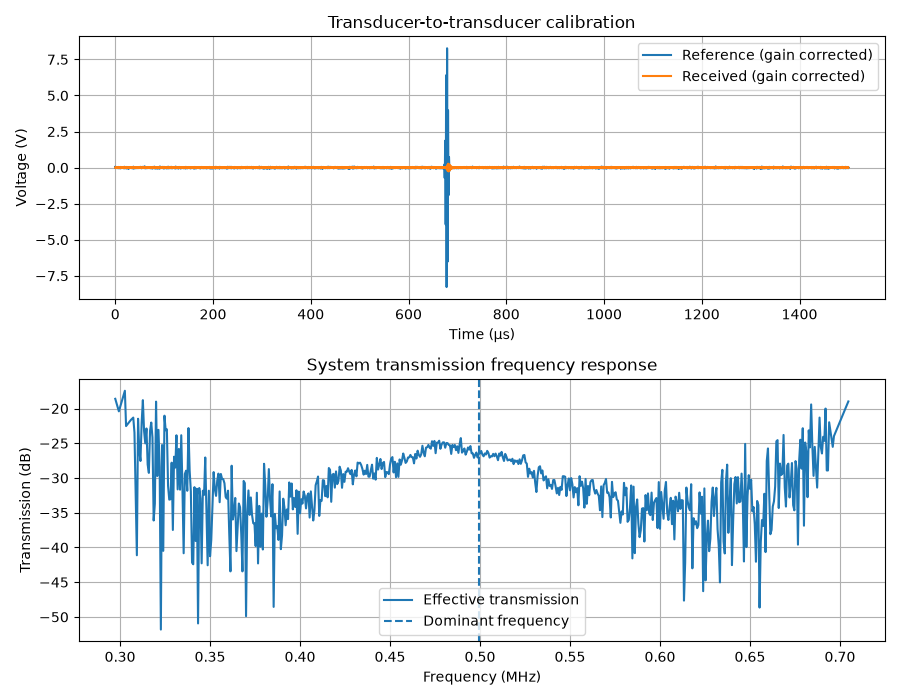

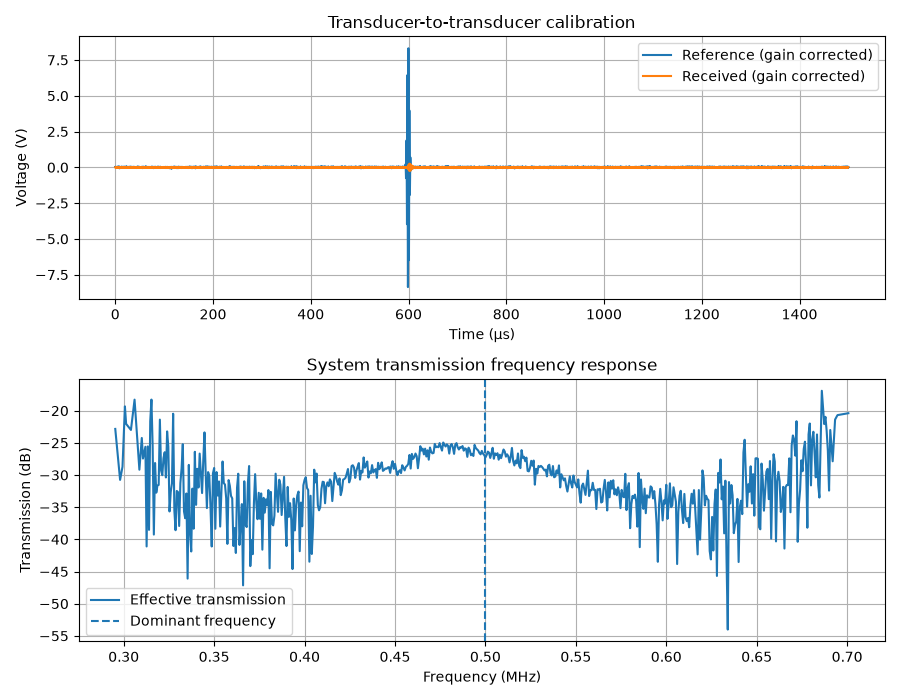

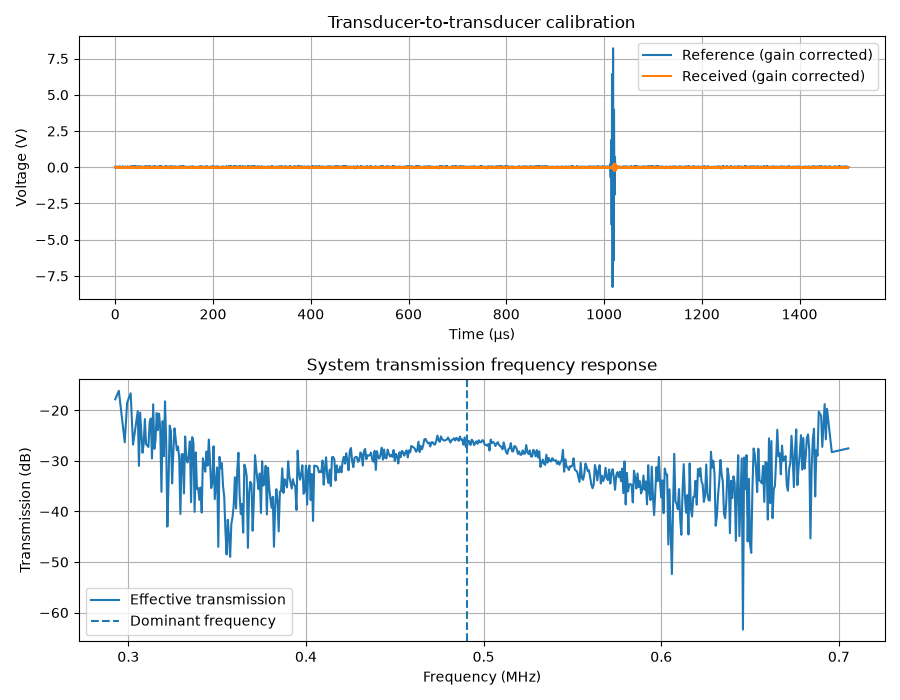

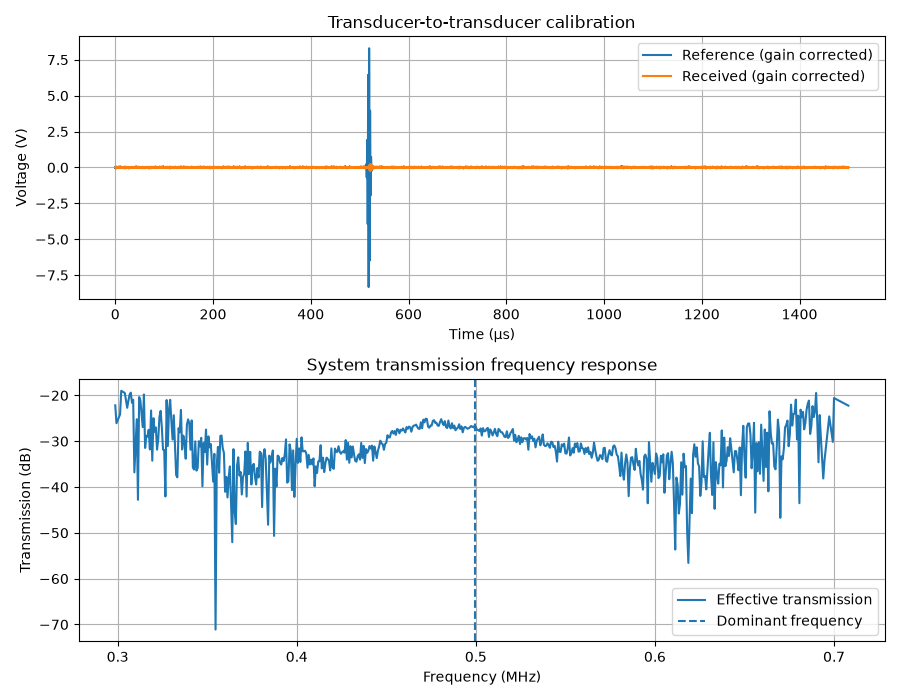

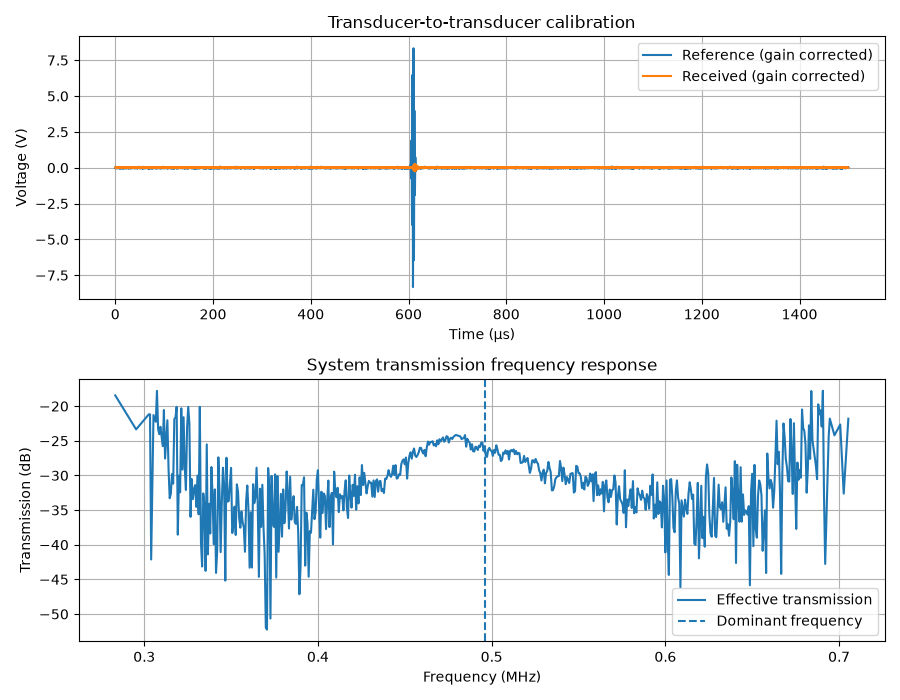

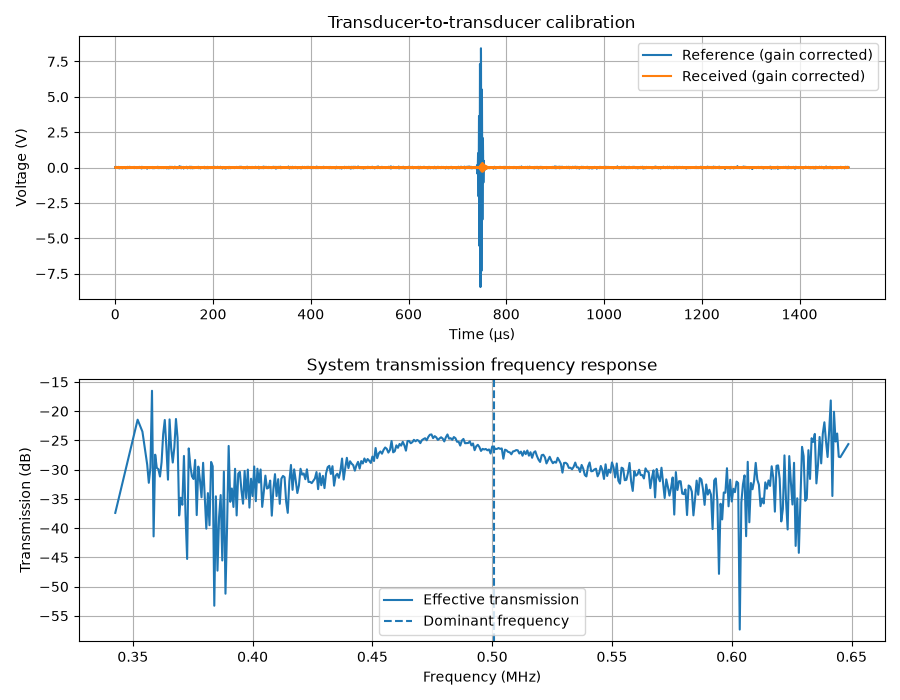

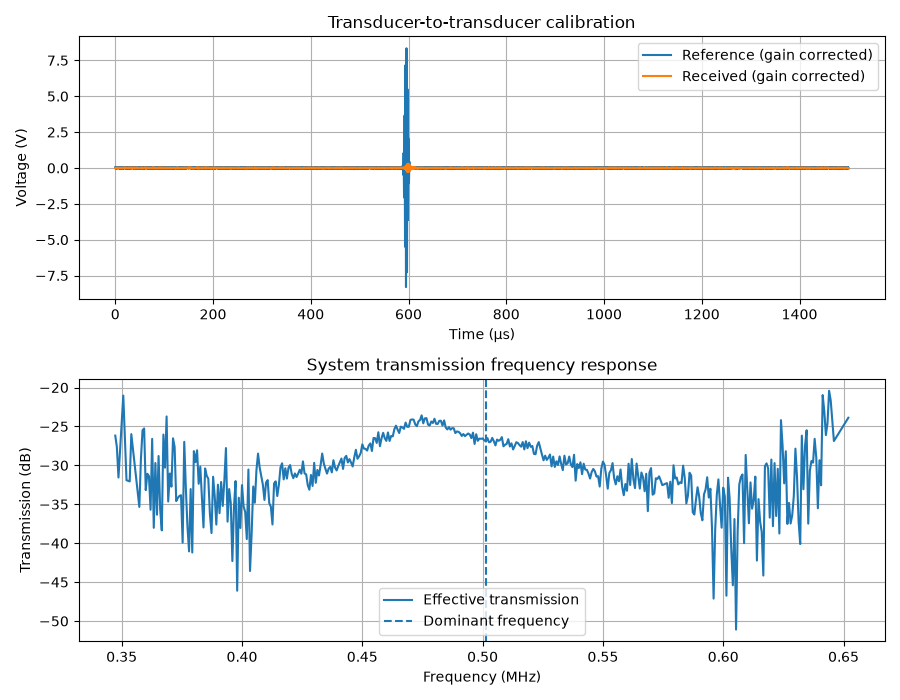

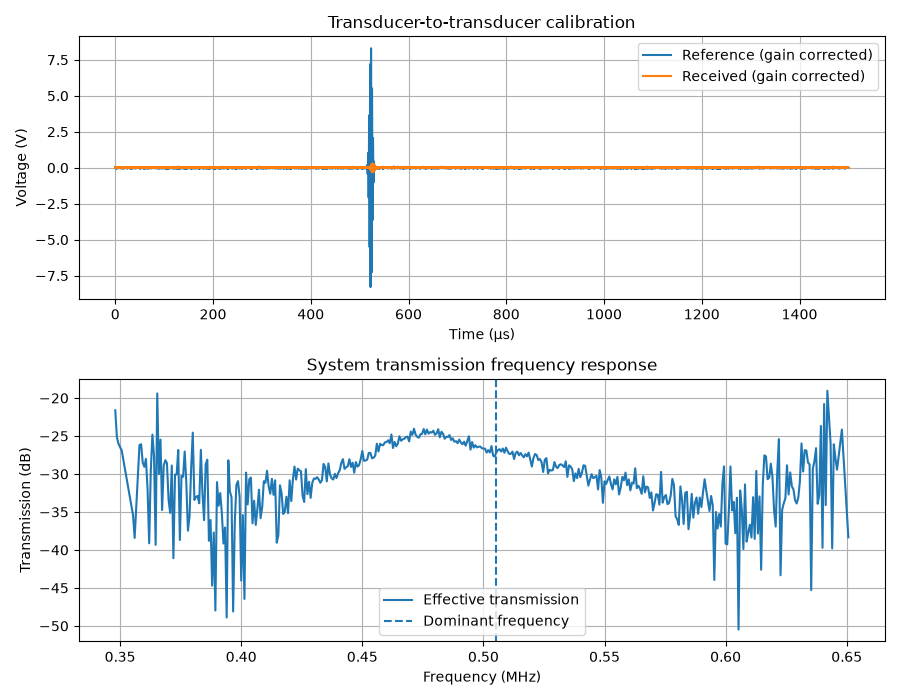

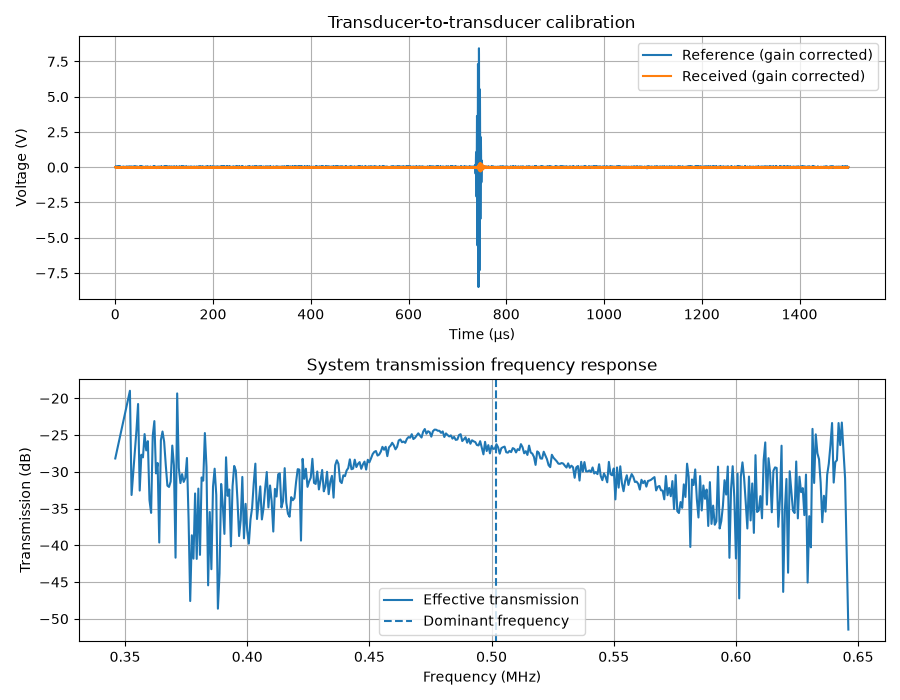

In [59]:

def calculate_system_transmission(
    time,
    reference_signal,
    received_signal,
    f_min=0.1e6,
    f_max=10e6,
    reference_gain_db=0.0,
    received_gain_db=0.0
):
    """
    Calculate effective transducer-to-transducer voltage transmission.

    Gain values are in dB and represent amplification applied
    to each measured signal.

    Returns:
        dominant_frequency_hz
        transmission_coefficient
        transmission_db
    """

    time = np.asarray(time, dtype=float)
    reference_signal = np.asarray(reference_signal, dtype=float)
    received_signal = np.asarray(received_signal, dtype=float)

    if not (len(time) == len(reference_signal) == len(received_signal)):
        raise ValueError("All arrays must have equal lengths.")

    if len(time) < 2:
        raise ValueError("At least two samples are required.")

    dt = np.median(np.diff(time))

    if dt <= 0:
        raise ValueError("Time values must be increasing.")

    # Remove DC offsets
    reference_signal = reference_signal - np.mean(reference_signal)
    received_signal = received_signal - np.mean(received_signal)

    # Convert channel gains from dB to linear amplitude factors
    reference_gain = 10 ** (reference_gain_db / 20)
    received_gain = 1/10 ** (received_gain_db / 20)

    # Remove amplification from each measured channel
    reference_corrected = reference_signal * reference_gain
    received_corrected = received_signal * received_gain

    # FFT of gain-corrected signals
    frequencies = np.fft.rfftfreq(len(time), d=dt)

    reference_fft = np.abs(np.fft.rfft(reference_corrected))/2
    received_fft = np.abs(np.fft.rfft(received_corrected))/2

    # Select analysis band
    band = (frequencies >= f_min) & (frequencies <= f_max)

    if not np.any(band):
        raise ValueError("No FFT bins inside selected frequency range.")

    # Dominant frequency of reference signal
    band_indices = np.flatnonzero(band)
    peak_idx = band_indices[np.argmax(reference_fft[band])]

    reference_amplitude = reference_fft[peak_idx]
    received_amplitude = received_fft[peak_idx]

    if reference_amplitude <= 0 or received_amplitude <= 0:
        raise ValueError("Spectral amplitudes must be positive.")

    # Effective voltage transmission coefficient
    transmission = received_amplitude / reference_amplitude

    # Transmission expressed in dB
    transmission_db = 20 * np.log10(transmission)

    # Frequency-dependent transmission
    valid = band & (
        reference_fft > np.max(reference_fft[band]) * 0.05
    )

    transmission_spectrum = (
        received_fft[valid] / reference_fft[valid]
    )

    transmission_spectrum_db = 20 * np.log10(
        np.maximum(transmission_spectrum, np.finfo(float).tiny)
    )

    # Plot results
    fig, axes = plt.subplots(2, 1, figsize=(9, 7))

    axes[0].plot(
        time * 1e6,
        reference_corrected,
        label="Reference (gain corrected)"
    )

    axes[0].plot(
        time * 1e6,
        received_corrected,
        label="Received (gain corrected)"
    )

    axes[0].set_title("Transducer-to-transducer calibration")
    axes[0].set_xlabel("Time (µs)")
    axes[0].set_ylabel("Voltage (V)")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(
        frequencies[valid] / 1e6,
        transmission_spectrum_db,
        label="Effective transmission"
    )

    axes[1].axvline(
        frequencies[peak_idx] / 1e6,
        linestyle="--",
        label="Dominant frequency"
    )

    axes[1].set_title("System transmission frequency response")
    axes[1].set_xlabel("Frequency (MHz)")
    axes[1].set_ylabel("Transmission (dB)")
    axes[1].legend()
    axes[1].grid(True)

    fig.tight_layout()

    return (
        float(frequencies[peak_idx]),
        float(transmission),
        float(transmission_db)
    )


results = []

for i in range(1, 10):

    data = pd.read_csv(
        f"data/Wringed/{i}.csv"
    )

    frequency, transmission, transmission_db = (
        calculate_system_transmission(
            time=data["time_s"].to_numpy(),
            reference_signal=data["reference_v"].to_numpy(),
            received_signal=data["measured_v"].to_numpy(),
            f_min=0.1e6,
            f_max=10e6,
            reference_gain_db=4.989,  # Change to actual reference gain
            received_gain_db=4.989    # Change to actual received gain
        )
    )

    results.append({
        "Measurement": i,
        "Frequency (MHz)": frequency / 1e6,
        "Transmission": transmission,
        "Transmission (dB)": transmission_db
    })

    print(
        f"Measurement {i}: "
        f"T = {transmission:.5f}, "
        f"Transmission = {transmission_db:.3f} dB"
    )

results_df = pd.DataFrame(results)

print("\nSystem transmission summary:")
print(results_df.to_string(index=False))

print(f"\nMean transmission: {results_df['Transmission'].mean():.5f}")
print(f"Sample standard deviation: {results_df['Transmission'].std(ddof=1):.8f}")
print(f"Mean transmission (dB): {results_df['Transmission (dB)'].mean():.8f} dB")
print(f"Sample standard deviation (dB): {results_df['Transmission (dB)'].std(ddof=1):.8f} dB")


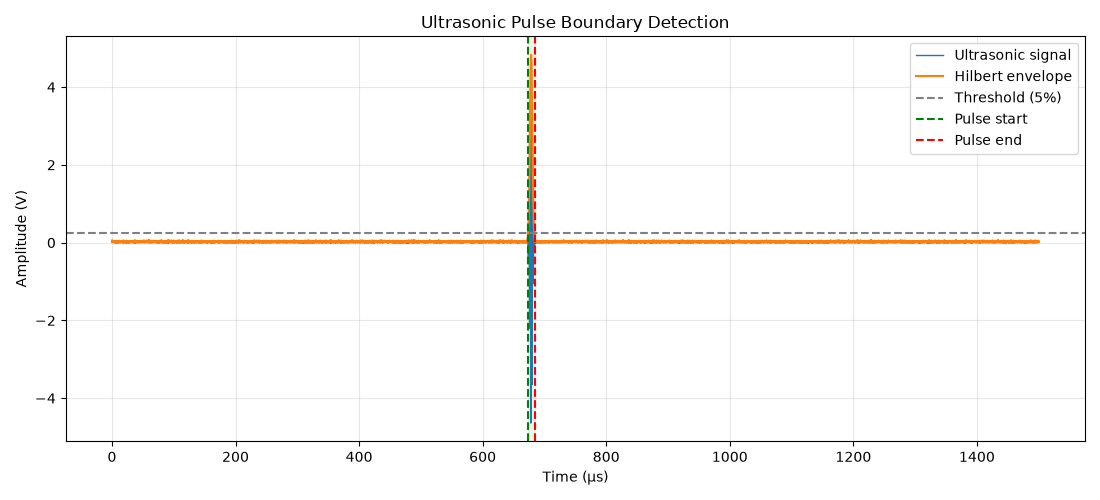

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert


def get_pulse_bounds(
    y: np.ndarray,
    cutoff_percentage: float = 0.05,
    time_cutoff_expander: int = 10
):
    # Calculate Hilbert envelope
    envelope = np.abs(hilbert(y))

    # Threshold relative to maximum envelope amplitude
    threshold = np.max(envelope) * cutoff_percentage
    max_idx = np.argmax(envelope)

    # Find contiguous region above threshold containing maximum
    above_threshold = envelope > threshold

    start = max_idx
    end = max_idx

    while start > 0 and above_threshold[start - 1]:
        start -= 1

    while end < len(y) - 1 and above_threshold[end + 1]:
        end += 1

    # Expand pulse boundaries
    start = max(0, start - time_cutoff_expander)
    end = min(len(y) - 1, end + time_cutoff_expander)

    return start, end, envelope, threshold


def plot_pulse_detection(
    time: np.ndarray,
    y: np.ndarray,
    cutoff_percentage: float = 0.05,
    time_cutoff_expander: int = 10
):
    start, end, envelope, threshold = get_pulse_bounds(
        y, cutoff_percentage, time_cutoff_expander
    )

    # Convert seconds to microseconds
    time_us = time * 1e6

    fig, ax = plt.subplots(figsize=(11, 5))

    ax.plot(time_us, y, label="Ultrasonic signal", linewidth=1)
    ax.plot(
        time_us, envelope,
        label="Hilbert envelope",
        linewidth=1.5
    )

    ax.axhline(
        threshold,
        linestyle="--",
        color="gray",
        label=f"Threshold ({cutoff_percentage * 100:g}%)"
    )

    ax.axvline(
        time_us[start],
        color="green",
        linestyle="--",
        label="Pulse start"
    )

    ax.axvline(
        time_us[end],
        color="red",
        linestyle="--",
        label="Pulse end"
    )

    ax.axvspan(
        time_us[start],
        time_us[end],
        color="green",
        alpha=0.08
    )

    ax.set_xlabel("Time (µs)")
    ax.set_ylabel("Amplitude (V)")
    ax.set_title("Ultrasonic Pulse Boundary Detection")
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

    return start, end

data = pd.read_csv(
        f"data/{1}.csv"
    )

start, end = plot_pulse_detection(
    data["time_s"].to_numpy(),
    data["reference_v"].to_numpy(),
    cutoff_percentage=0.05,
    time_cutoff_expander=10
)

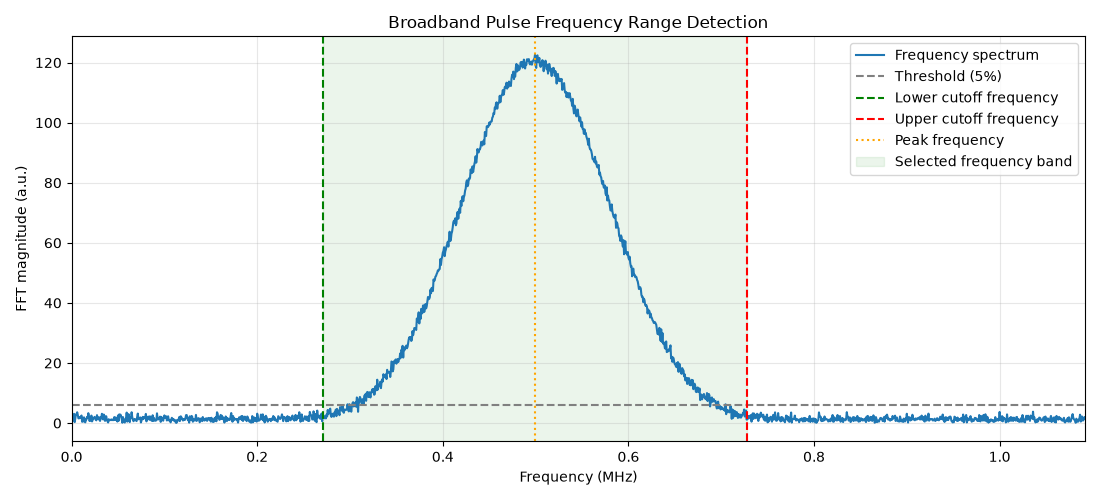

Peak frequency: 0.499 MHz
Lower cutoff: 0.271 MHz
Upper cutoff: 0.728 MHz
Selected bandwidth: 0.457 MHz


In [21]:
import numpy as np
import matplotlib.pyplot as plt


def plot_frequency_spectra_range(
    time: np.ndarray,
    y: np.ndarray,
    cutoff_percentage: float = 0.05,
    cutoff_expander: int = 10,
    min_cutoff_frequency: float = 0.0
):
    # Obtain frequency limits using your existing function
    min_cutoff, max_cutoff, sample_spacing = (
        get_frequency_spectra_range(
            time,
            y,
            cutoff_percentage,
            cutoff_expander,
            min_cutoff_frequency
        )
    )

    # Calculate frequency spectrum
    spectrum = np.fft.rfft(y)
    frequencies = np.fft.rfftfreq(
        len(y),
        d=sample_spacing
    )

    magnitude = np.abs(spectrum)

    # Apply initial minimum frequency restriction
    filtered_magnitude = magnitude.copy()
    filtered_magnitude[
        frequencies <= min_cutoff_frequency
    ] = 0

    # Determine peak frequency and threshold
    peak_idx = np.argmax(filtered_magnitude)
    peak_frequency = frequencies[peak_idx]

    threshold = (
        np.max(filtered_magnitude) * cutoff_percentage
    )

    # Convert frequencies to MHz
    frequencies_mhz = frequencies / 1e6
    min_cutoff_mhz = min_cutoff / 1e6
    max_cutoff_mhz = max_cutoff / 1e6
    peak_frequency_mhz = peak_frequency / 1e6

    # Plot
    fig, ax = plt.subplots(figsize=(11, 5))

    ax.plot(
        frequencies_mhz,
        filtered_magnitude,
        label="Frequency spectrum",
        linewidth=1.5
    )

    ax.axhline(
        threshold,
        color="gray",
        linestyle="--",
        label=f"Threshold ({cutoff_percentage * 100:g}%)"
    )

    ax.axvline(
        min_cutoff_mhz,
        color="green",
        linestyle="--",
        label="Lower cutoff frequency"
    )

    ax.axvline(
        max_cutoff_mhz,
        color="red",
        linestyle="--",
        label="Upper cutoff frequency"
    )

    ax.axvline(
        peak_frequency_mhz,
        color="orange",
        linestyle=":",
        label="Peak frequency"
    )

    # Highlight selected frequency range
    ax.axvspan(
        min_cutoff_mhz,
        max_cutoff_mhz,
        color="green",
        alpha=0.08,
        label="Selected frequency band"
    )

    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("FFT magnitude (a.u.)")
    ax.set_title("Broadband Pulse Frequency Range Detection")

    ax.grid(True, alpha=0.3)
    ax.legend()

    # Focus on the relevant spectrum
    ax.set_xlim(
        0,
        min(
            frequencies_mhz[-1],
            max_cutoff_mhz * 1.5
        )
    )

    plt.tight_layout()
    plt.show()

    print(f"Peak frequency: {peak_frequency_mhz:.3f} MHz")
    print(f"Lower cutoff: {min_cutoff_mhz:.3f} MHz")
    print(f"Upper cutoff: {max_cutoff_mhz:.3f} MHz")
    print(
        f"Selected bandwidth: "
        f"{(max_cutoff - min_cutoff) / 1e6:.3f} MHz"
    )

    return min_cutoff, max_cutoff

start, end = plot_frequency_spectra_range(
    data["time_s"].to_numpy(),
    data["reference_v"].to_numpy(),
    cutoff_percentage=0.05,
    cutoff_expander=10
)

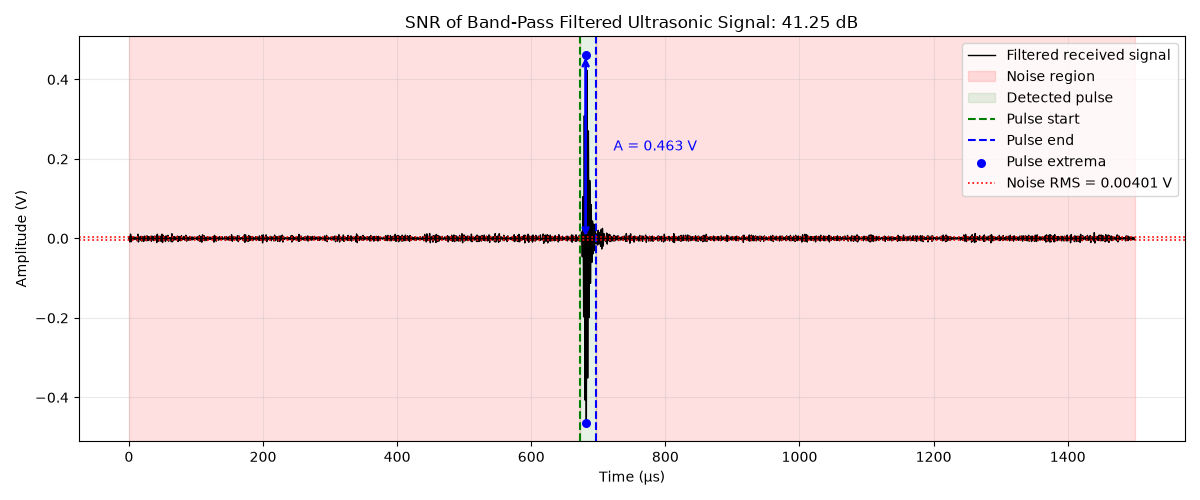

Frequency range: 0.271–0.728 MHz
Pulse start: 673.400 µs
Pulse end: 697.000 µs
Pulse amplitude: 0.463421 V
Noise RMS: 0.00401354 V
SNR after filtering: 41.25 dB


In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert


def plot_SNR(
    time: np.ndarray,
    reference: np.ndarray,
    measured: np.ndarray,
    cutoff_percentage: float = 0.05,
    frequency_cutoff_expander: int = 10,
    time_cutoff_expander: int = 20,
    min_cutoff_frequency: float = 0.0
):
    time = np.asarray(time)
    reference = np.asarray(reference)
    measured = np.asarray(measured)

    if not (
        time.ndim == reference.ndim == measured.ndim == 1
        and len(time) == len(reference) == len(measured)
        and len(time) >= 2
    ):
        raise ValueError("Input arrays must have equal lengths")

    # --------------------------------------------------
    # 1. Determine frequency range from reference signal
    # --------------------------------------------------

    f_min, f_max, spacing = get_frequency_spectra_range(
        time,
        reference,
        cutoff_percentage,
        frequency_cutoff_expander,
        min_cutoff_frequency
    )

    # --------------------------------------------------
    # 2. Apply frequency-domain band-pass filter
    # --------------------------------------------------

    filtered_reference = band_pass_filter(
        reference, f_min, f_max, spacing
    )

    filtered_measured = band_pass_filter(
        measured, f_min, f_max, spacing
    )

    y = filtered_measured

    # --------------------------------------------------
    # 3. Determine pulse boundaries using Hilbert envelope
    # --------------------------------------------------

    envelope = np.abs(hilbert(y))
    threshold = np.max(envelope) * cutoff_percentage

    peak_idx = np.argmax(envelope)
    above_threshold = envelope > threshold

    start = peak_idx
    end = peak_idx

    while start > 0 and above_threshold[start - 1]:
        start -= 1

    while end < len(y) - 1 and above_threshold[end + 1]:
        end += 1

    start = max(start - time_cutoff_expander, 0)
    end = min(end + time_cutoff_expander + 1, len(y))

    # --------------------------------------------------
    # 4. Extract pulse and noise regions
    # --------------------------------------------------

    pulse = y[start:end]

    noise = np.concatenate([
        y[:start],
        y[end:]
    ])

    if noise.size == 0:
        raise ValueError("No samples remain for noise calculation")

    # --------------------------------------------------
    # 5. Calculate pulse amplitude, noise RMS and SNR
    # --------------------------------------------------

    A_max = np.max(pulse)
    A_min = np.min(pulse)

    A_pulse = (A_max - A_min) / 2
    A_mid = (A_max + A_min) / 2

    N_rms = np.sqrt(np.mean(noise**2))

    if A_pulse <= 0 or N_rms <= 0:
        raise ValueError("Pulse amplitude and noise RMS must be positive")

    snr_db = 20 * np.log10(A_pulse / N_rms)

    max_idx = start + np.argmax(pulse)
    min_idx = start + np.argmin(pulse)

    # --------------------------------------------------
    # 6. Plot filtered signal and SNR regions
    # --------------------------------------------------

    time_us = time * 1e6

    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        time_us,
        y,
        color="black",
        linewidth=1,
        label="Filtered received signal"
    )

    # Noise regions
    if start > 0:
        ax.axvspan(
            time_us[0],
            time_us[start],
            color="red",
            alpha=0.12,
            label="Noise region"
        )

    if end < len(y):
        ax.axvspan(
            time_us[end],
            time_us[-1],
            color="red",
            alpha=0.12
        )

    # Pulse region
    ax.axvspan(
        time_us[start],
        time_us[end - 1],
        color="green",
        alpha=0.10,
        label="Detected pulse"
    )

    # Pulse boundaries
    ax.axvline(
        time_us[start],
        color="green",
        linestyle="--",
        label="Pulse start"
    )

    ax.axvline(
        time_us[end - 1],
        color="blue",
        linestyle="--",
        label="Pulse end"
    )

    # Pulse extrema
    ax.scatter(
        [time_us[max_idx], time_us[min_idx]],
        [A_max, A_min],
        color="blue",
        s=30,
        zorder=5,
        label="Pulse extrema"
    )

    # Pulse amplitude arrow
    arrow_x = time_us[max_idx]

    ax.annotate(
        "",
        xy=(arrow_x, A_max),
        xytext=(arrow_x, A_mid),
        arrowprops=dict(
            arrowstyle="<->",
            color="blue",
            linewidth=2
        )
    )

    ax.annotate(
        f"A = {A_pulse:.3g} V",
        xy=(arrow_x, (A_max + A_mid) / 2),
        xytext=(20, 0),
        textcoords="offset points",
        va="center",
        color="blue"
    )

    # RMS noise levels
    ax.axhline(
        N_rms,
        color="red",
        linestyle=":",
        linewidth=1.2,
        label=f"Noise RMS = {N_rms:.3g} V"
    )

    ax.axhline(
        -N_rms,
        color="red",
        linestyle=":",
        linewidth=1.2
    )

    ax.set_xlabel("Time (µs)")
    ax.set_ylabel("Amplitude (V)")
    ax.set_title(
        f"SNR of Band-Pass Filtered Ultrasonic Signal: {snr_db:.2f} dB"
    )

    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")

    plt.tight_layout()
    plt.show()

    print(f"Frequency range: {f_min/1e6:.3f}–{f_max/1e6:.3f} MHz")
    print(f"Pulse start: {time_us[start]:.3f} µs")
    print(f"Pulse end: {time_us[end-1]:.3f} µs")
    print(f"Pulse amplitude: {A_pulse:.6g} V")
    print(f"Noise RMS: {N_rms:.6g} V")
    print(f"SNR after filtering: {snr_db:.2f} dB")

    return start, end, snr_db

start, end, snr_db = plot_SNR(
    data["time_s"].to_numpy(),
    data["reference_v"].to_numpy(),
    data["measured_v"].to_numpy(),
    cutoff_percentage=0.05,
    frequency_cutoff_expander=10,
    time_cutoff_expander=20
)

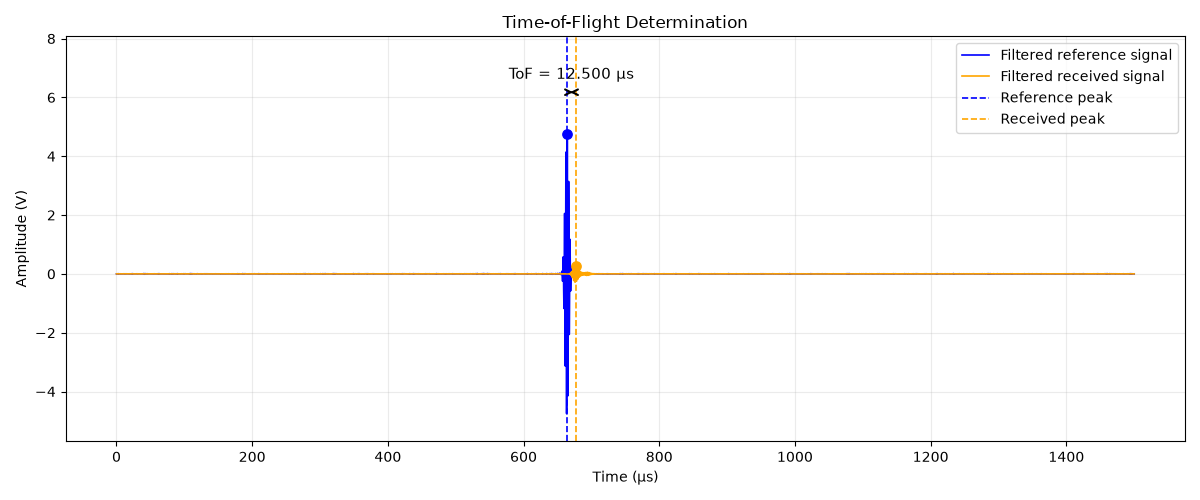

Reference peak: 664.4000 µs
Received peak: 676.9000 µs
Time of flight: 12.5000 µs


In [33]:
import numpy as np
import matplotlib.pyplot as plt


def plot_ToF(
    time: np.ndarray,
    reference: np.ndarray,
    measured: np.ndarray,
    cutoff_percentage: float = 0.05,
    frequency_cutoff_expander: int = 10,
    min_cutoff_frequency: float = 0.0,
    ref_db_gain: float = 0.0,
    measured_db_gain: float = 0.0
):
    """
    Visualise the time of flight between the maximum positive
    amplitudes of the filtered reference and received pulses.

    Time input is assumed to be in seconds.
    """

    time = np.asarray(time)
    reference = np.asarray(reference)
    measured = np.asarray(measured)

    if not (
        time.ndim == reference.ndim == measured.ndim == 1
        and len(time) == len(reference) == len(measured)
        and len(time) >= 2
    ):
        raise ValueError("Input arrays must have equal lengths")

    # --------------------------------------------------
    # 1. Determine frequency range from reference
    # --------------------------------------------------

    f_min, f_max, spacing = get_frequency_spectra_range(
        time,
        reference,
        cutoff_percentage,
        frequency_cutoff_expander,
        min_cutoff_frequency
    )

    # --------------------------------------------------
    # 2. Apply gain correction factors
    # --------------------------------------------------

    reference = reference * get_gain_factor(
        "out", ref_db_gain
    )

    measured = measured * get_gain_factor(
        "out", measured_db_gain
    )

    # --------------------------------------------------
    # 3. Apply frequency-domain band-pass filter
    # --------------------------------------------------

    filtered_reference = band_pass_filter(
        reference, f_min, f_max, spacing
    )

    filtered_measured = band_pass_filter(
        measured, f_min, f_max, spacing
    )

    # --------------------------------------------------
    # 4. Determine maximum positive amplitude positions
    # --------------------------------------------------

    ref_peak_idx = np.argmax(filtered_reference)
    measured_peak_idx = np.argmax(filtered_measured)

    if measured_peak_idx < ref_peak_idx:
        raise ValueError(
            "Received pulse maximum occurs before reference maximum"
        )

    ref_peak_time = time[ref_peak_idx]
    measured_peak_time = time[measured_peak_idx]

    ref_peak_amplitude = filtered_reference[ref_peak_idx]
    measured_peak_amplitude = filtered_measured[measured_peak_idx]

    # Time of flight
    tof = measured_peak_time - ref_peak_time

    # --------------------------------------------------
    # 5. Plot
    # --------------------------------------------------

    time_us = time * 1e6
    ref_time_us = ref_peak_time * 1e6
    measured_time_us = measured_peak_time * 1e6
    tof_us = tof * 1e6

    fig, ax = plt.subplots(figsize=(12, 5))

    # Filtered signals
    ax.plot(
        time_us,
        filtered_reference,
        color="blue",
        linewidth=1.2,
        label="Filtered reference signal"
    )

    ax.plot(
        time_us,
        filtered_measured,
        color="orange",
        linewidth=1.2,
        label="Filtered received signal"
    )

    # Peak markers
    ax.scatter(
        ref_time_us,
        ref_peak_amplitude,
        color="blue",
        s=45,
        zorder=5
    )

    ax.scatter(
        measured_time_us,
        measured_peak_amplitude,
        color="orange",
        s=45,
        zorder=5
    )

    # Vertical peak lines
    ax.axvline(
        ref_time_us,
        color="blue",
        linestyle="--",
        linewidth=1.2,
        label="Reference peak"
    )

    ax.axvline(
        measured_time_us,
        color="orange",
        linestyle="--",
        linewidth=1.2,
        label="Received peak"
    )

    # --------------------------------------------------
    # 6. ToF double-headed arrow
    # --------------------------------------------------

    # Position arrow above both signal peaks
    signal_max = max(
        np.max(filtered_reference),
        np.max(filtered_measured)
    )

    signal_min = min(
        np.min(filtered_reference),
        np.min(filtered_measured)
    )

    amplitude_range = signal_max - signal_min

    arrow_y = signal_max + 0.15 * amplitude_range

    ax.annotate(
        "",
        xy=(measured_time_us, arrow_y),
        xytext=(ref_time_us, arrow_y),
        arrowprops=dict(
            arrowstyle="<->",
            color="black",
            linewidth=1.5
        )
    )

    # ToF label
    ax.text(
        (ref_time_us + measured_time_us) / 2,
        arrow_y + 0.035 * amplitude_range,
        f"ToF = {tof_us:.3f} µs",
        ha="center",
        va="bottom",
        fontsize=11
    )

    # Expand vertical limits to accommodate arrow
    ax.set_ylim(
        signal_min - 0.1 * amplitude_range,
        signal_max + 0.35 * amplitude_range
    )

    ax.set_xlabel("Time (µs)")
    ax.set_ylabel("Amplitude (V)")
    ax.set_title("Time-of-Flight Determination")

    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")

    plt.tight_layout()
    plt.show()

    print(f"Reference peak: {ref_time_us:.4f} µs")
    print(f"Received peak: {measured_time_us:.4f} µs")
    print(f"Time of flight: {tof_us:.4f} µs")

    return tof, (ref_peak_time, ref_peak_amplitude), (
        measured_peak_time, measured_peak_amplitude
    )

data = pd.read_csv(
        f"data/Test/{1}.csv"
    )

tof, ref_peak, measured_peak = plot_ToF(
    data["time_s"].to_numpy(),
    data["reference_v"].to_numpy(),
    data["measured_v"].to_numpy(),
    cutoff_percentage=0.05,
    frequency_cutoff_expander=10,
    ref_db_gain=0.0,
    measured_db_gain=6
)

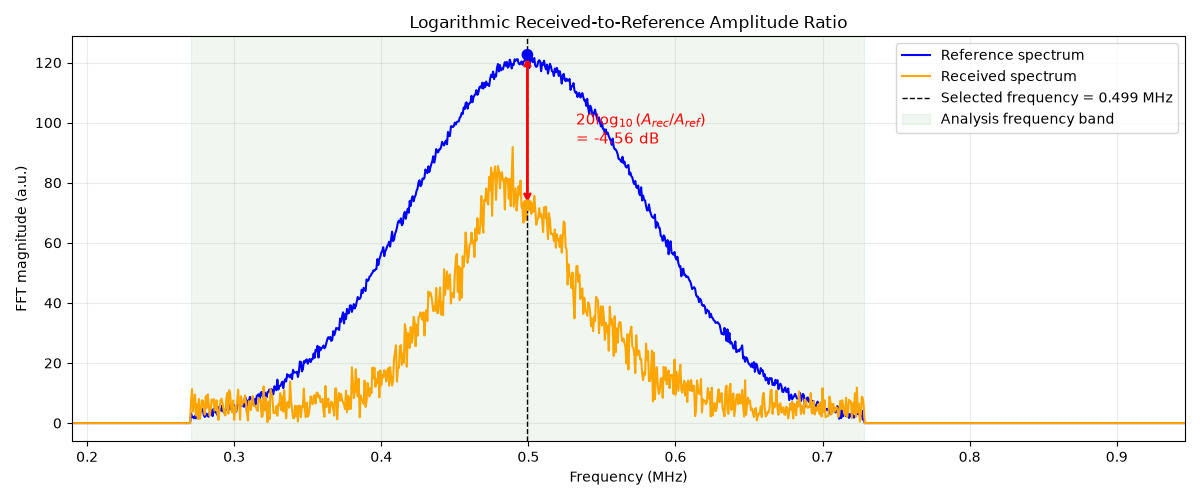

Selected frequency: 0.4993 MHz
Reference amplitude: 122.607
Received amplitude: 72.5066
Logarithmic amplitude ratio: -4.5628 dB


In [38]:
import numpy as np
import matplotlib.pyplot as plt


def plot_amplitude_ratio(
    time: np.ndarray,
    reference: np.ndarray,
    measured: np.ndarray,
    cutoff_percentage: float = 0.05,
    frequency_cutoff_expander: int = 10,
    min_cutoff_frequency: float = 0.0,
    ref_db_gain: float = 0.0,
    measured_db_gain: float = 0.0
):
    """
    Plot reference and received FFT magnitudes and determine
    their logarithmic amplitude ratio at the reference
    spectrum's maximum frequency.

    Returns
    -------
    peak_frequency : float
        Selected frequency in Hz.
    ratio_db : float
        20*log10(A_received / A_reference), in dB.
    """

    time = np.asarray(time)
    reference = np.asarray(reference)
    measured = np.asarray(measured)

    if not (
        time.ndim == reference.ndim == measured.ndim == 1
        and len(time) == len(reference) == len(measured)
        and len(time) >= 2
    ):
        raise ValueError("Input arrays must be equal-length 1D arrays")

    spacing = np.median(np.diff(time))

    if not np.isfinite(spacing) or spacing <= 0:
        raise ValueError("Invalid time spacing")

    # --------------------------------------------------
    # 1. Determine effective frequency range
    # --------------------------------------------------

    f_min, f_max, spacing = get_frequency_spectra_range(
        time,
        reference,
        cutoff_percentage,
        frequency_cutoff_expander,
        min_cutoff_frequency
    )

    # --------------------------------------------------
    # 2. Apply gain correction factors
    # --------------------------------------------------

    reference = reference * get_gain_factor(
        "out", ref_db_gain
    )

    measured = measured * get_gain_factor(
        "out", measured_db_gain
    )

    # --------------------------------------------------
    # 3. Apply frequency-domain band-pass filter
    # --------------------------------------------------

    filtered_reference = band_pass_filter(
        reference, f_min, f_max, spacing
    )

    filtered_measured = band_pass_filter(
        measured, f_min, f_max, spacing
    )

    # --------------------------------------------------
    # 4. Calculate FFT magnitudes
    # --------------------------------------------------

    frequencies = np.fft.rfftfreq(
        len(time), d=spacing
    )

    spectrum_reference = np.abs(
        np.fft.rfft(filtered_reference)
    )

    spectrum_measured = np.abs(
        np.fft.rfft(filtered_measured)
    )

    # Select frequency bins inside analysis range
    frequency_indices = np.where(
        (frequencies >= f_min) &
        (frequencies <= f_max)
    )[0]

    if frequency_indices.size == 0:
        raise ValueError("No frequency bins in selected range")

    # --------------------------------------------------
    # 5. Find maximum reference spectral amplitude
    # --------------------------------------------------

    local_peak_idx = np.argmax(
        spectrum_reference[frequency_indices]
    )

    peak_idx = frequency_indices[local_peak_idx]

    peak_frequency = frequencies[peak_idx]

    A_ref = spectrum_reference[peak_idx]
    A_rec = spectrum_measured[peak_idx]

    if A_ref <= 0 or A_rec <= 0:
        raise ValueError("Spectral amplitudes must be positive")

    # Signed logarithmic amplitude ratio
    ratio_db = 20 * np.log10(A_rec / A_ref)

    # --------------------------------------------------
    # 6. Plot spectra
    # --------------------------------------------------

    frequencies_mhz = frequencies / 1e6
    peak_frequency_mhz = peak_frequency / 1e6

    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        frequencies_mhz,
        spectrum_reference,
        color="blue",
        linewidth=1.5,
        label="Reference spectrum"
    )

    ax.plot(
        frequencies_mhz,
        spectrum_measured,
        color="orange",
        linewidth=1.5,
        label="Received spectrum"
    )

    # Selected frequency
    ax.axvline(
        peak_frequency_mhz,
        color="black",
        linestyle="--",
        linewidth=1,
        label=f"Selected frequency = {peak_frequency_mhz:.3f} MHz"
    )

    # Amplitude markers
    ax.scatter(
        [peak_frequency_mhz, peak_frequency_mhz],
        [A_ref, A_rec],
        color=["blue", "orange"],
        s=55,
        zorder=5
    )

    # Arrow between spectral amplitudes
    ax.annotate(
        "",
        xy=(peak_frequency_mhz, A_ref),
        xytext=(peak_frequency_mhz, A_rec),
        arrowprops=dict(
            arrowstyle="<->",
            color="red",
            linewidth=2
        )
    )

    # Logarithmic ratio annotation
    ax.annotate(
        f"$20\\log_{{10}}(A_{{rec}}/A_{{ref}})$"
        f"\n= {ratio_db:.2f} dB",
        xy=(peak_frequency_mhz, (A_ref + A_rec) / 2),
        xytext=(35, 0),
        textcoords="offset points",
        va="center",
        color="red",
        fontsize=11
    )

    # Selected analysis band
    ax.axvspan(
        f_min / 1e6,
        f_max / 1e6,
        color="green",
        alpha=0.06,
        label="Analysis frequency band"
    )

    ax.set_xlim(
        max(0, f_min / 1e6 * 0.7),
        min(frequencies_mhz[-1], f_max / 1e6 * 1.3)
    )

    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("FFT magnitude (a.u.)")
    ax.set_title("Logarithmic Received-to-Reference Amplitude Ratio")

    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")

    plt.tight_layout()
    plt.show()

    print(f"Selected frequency: {peak_frequency_mhz:.4f} MHz")
    print(f"Reference amplitude: {A_ref:.6g}")
    print(f"Received amplitude: {A_rec:.6g}")
    print(f"Logarithmic amplitude ratio: {ratio_db:.4f} dB")

    return peak_frequency, ratio_db

data = pd.read_csv(
        f"data/Wringed/{1}.csv"
    )

peak_frequency, ratio_db = plot_amplitude_ratio(
    data["time_s"].to_numpy(),
    data["reference_v"].to_numpy(),
    data["measured_v"].to_numpy(),
    cutoff_percentage=0.05,
    frequency_cutoff_expander=10,
    ref_db_gain=0.0,
    measured_db_gain=12
)

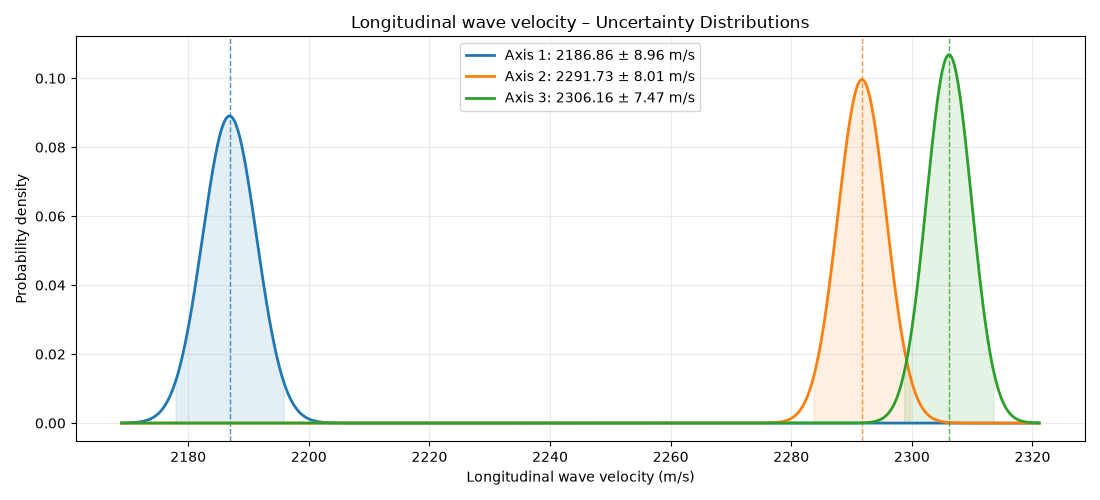

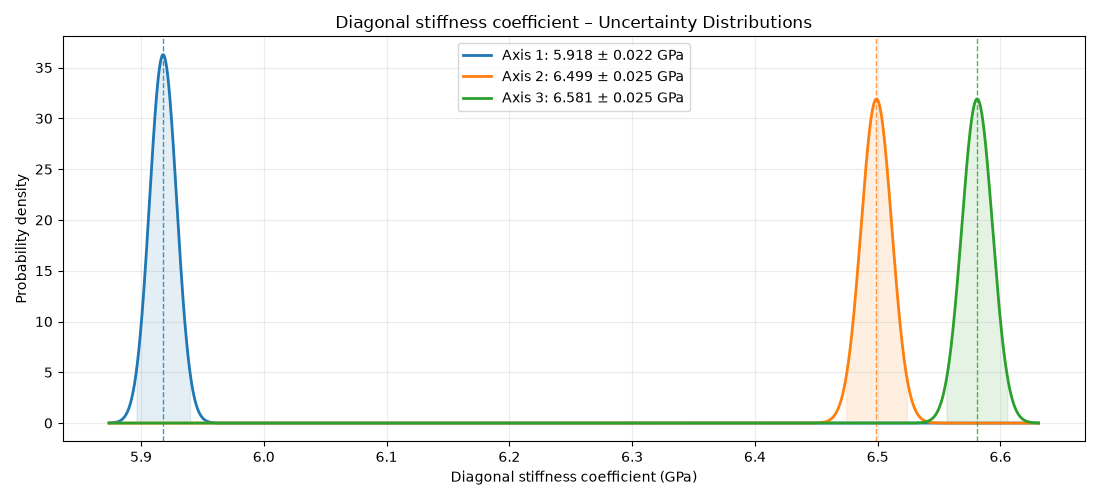

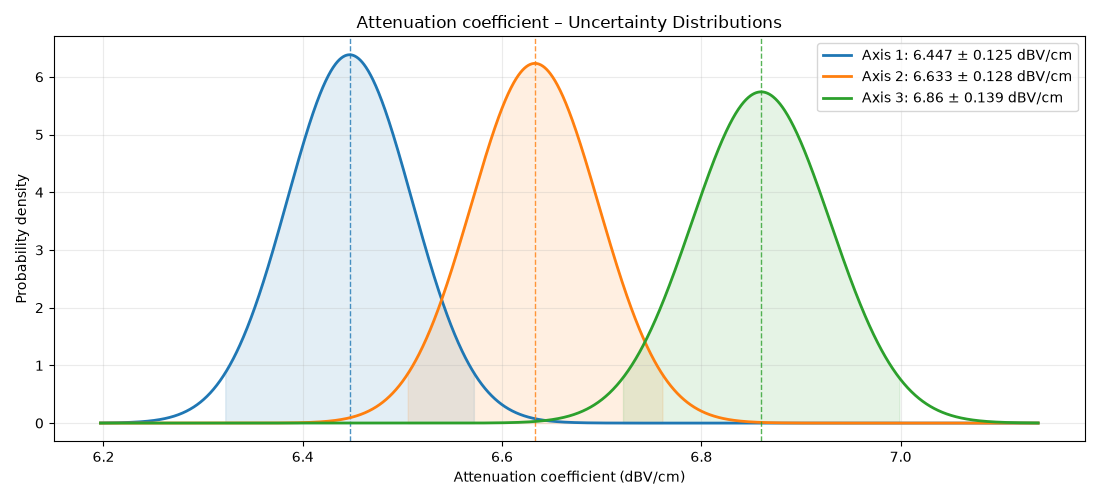

(<Figure size 1100x500 with 1 Axes>,
 <Axes: title={'center': 'Attenuation coefficient – Uncertainty Distributions'}, xlabel='Attenuation coefficient (dBV/cm)', ylabel='Probability density'>)

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


def plot_property_distributions(
    means,
    expanded_uncertainties,
    property_name,
    unit,
    coverage_factor=2,
    show_coverage=True
):
    """
    Plot normal uncertainty distributions for three principal axes.

    Parameters
    ----------
    means : array-like
        Mean property values for Axes 1, 2 and 3.

    expanded_uncertainties : array-like
        Expanded uncertainties for the three axes.

    property_name : str
        Name of the material property.

    unit : str
        Unit of the material property.

    coverage_factor : float
        Coverage factor used to calculate expanded uncertainties.

    show_coverage : bool
        Whether to shade the ± expanded uncertainty intervals.
    """

    means = np.asarray(means, dtype=float)
    expanded_uncertainties = np.asarray(
        expanded_uncertainties, dtype=float
    )

    if means.shape != (3,) or expanded_uncertainties.shape != (3,):
        raise ValueError("Provide exactly three values for each input")

    if coverage_factor <= 0 or np.any(expanded_uncertainties <= 0):
        raise ValueError("Uncertainties and coverage factor must be positive")

    # Convert expanded uncertainties to standard uncertainties
    std = expanded_uncertainties / coverage_factor

    # Common x-axis range for all distributions
    x_min = np.min(means - 4 * std)
    x_max = np.max(means + 4 * std)

    x = np.linspace(x_min, x_max, 2000)

    colors = ["tab:blue", "tab:orange", "tab:green"]

    fig, ax = plt.subplots(figsize=(11, 5))

    for i in range(3):

        y = norm.pdf(x, loc=means[i], scale=std[i])

        ax.plot(
            x,
            y,
            color=colors[i],
            linewidth=2,
            label=(
                f"Axis {i+1}: "
                f"{means[i]:g} ± {expanded_uncertainties[i]:g} {unit}"
            )
        )

        # Mark mean value
        ax.axvline(
            means[i],
            color=colors[i],
            linestyle="--",
            linewidth=1,
            alpha=0.8
        )

        if show_coverage:

            mask = (
                (x >= means[i] - expanded_uncertainties[i]) &
                (x <= means[i] + expanded_uncertainties[i])
            )

            ax.fill_between(
                x[mask],
                y[mask],
                color=colors[i],
                alpha=0.12
            )

    ax.set_xlabel(f"{property_name} ({unit})")
    ax.set_ylabel("Probability density")
    ax.set_title(f"{property_name} – Uncertainty Distributions")

    ax.grid(True, alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

    return fig, ax

plot_property_distributions(
    means=[2186.86, 2291.73, 2306.16],
    expanded_uncertainties=[8.96, 8.01, 7.47],
    property_name="Longitudinal wave velocity",
    unit="m/s"
)

plot_property_distributions(
    means=[5.918, 6.499, 6.581],
    expanded_uncertainties=[0.022, 0.025
, 0.025],
    property_name="Diagonal stiffness coefficient",
    unit="GPa"
)

plot_property_distributions(
    means=[6.447, 6.633, 6.860],
    expanded_uncertainties=[0.125, 0.128, 0.139],
    property_name="Attenuation coefficient",
    unit="dBV/cm"
)

In [47]:
import numpy as np
from scipy import signal
from typing import Literal

def get_max_band(array:np.ndarray,percentage:float)->tuple[int,int]:
    if array.ndim != 1 or array.size == 0:
        raise ValueError("Signal must be a non-empty one-dimensional array")
    if not 0 < percentage <= 1:
        raise ValueError("Cutoff percentage must be greater than 0 and at most 1")

    cuttoff_value=np.max(array)*percentage
    max_idx=np.argmax(array)

    idxs_greater_than_cutoff=np.where(array>cuttoff_value)[0]
    if idxs_greater_than_cutoff.size == 0:
        raise ValueError("No signal band exceeds the cutoff")
    if idxs_greater_than_cutoff.size == 1:
        index = int(idxs_greater_than_cutoff[0])
        return index, index
    difference_between_idxs=np.diff(idxs_greater_than_cutoff)

    is_one = difference_between_idxs == 1

    # False boundaries ensure runs touching either edge are detected.
    changes = np.diff(np.concatenate(([False], is_one, [False])).astype(int))


    starts = np.flatnonzero(changes == 1)
    ends = np.flatnonzero(changes == -1)

    global_start=0
    global_end=0

    for start, end in zip(starts, ends):
        band_start = idxs_greater_than_cutoff[start]
        band_end = idxs_greater_than_cutoff[end]
    
        if band_start <= max_idx <= band_end:
            global_start = int(band_start)
            global_end = int(band_end)
    
            break

    return global_start, global_end
       
def get_frequency_spectra_range(time:np.ndarray,y:np.ndarray,cutoff_percentage:float,cutoff_expander:int,min_cutoff_frequency:float=0.00)->tuple[float,float,float]:
    """
    Gets the min and max effective frequency range of a broadband pulse

    time: Time values (numpy array expected)
    y: Corresponding values for the time series (numpy array expected)
    cutoff_percentage: This perecntage of the maximum amplitude of the signal will determine the cutoff frequencies, anything below it will be treated as noise and removed.
    cutoff_expander: This integer value will expand the tip and tail of the band by increasing the width of the band
    min_cutoff_frequency: Initial cutoff to remove noise that is present at for example 0Hz (steady state noise) 

    Returns:
    Tuple[min_cutoff, max_cutoff, sample_spacing]

    Note: This will only work for a broadband pulse with one continious range, if seperate ranges are contained within the signal it will fail
    """
    # Assumes time_s is in seconds and samples are uniformly spaced
    if time.size != y.size or time.size < 2:
        raise ValueError("Time and signal arrays must have equal lengths of at least 2")
    sample_spacing = np.median(np.diff(time))
    if not np.isfinite(sample_spacing) or sample_spacing <= 0:
        raise ValueError("Time values must be finite and strictly increasing")

    # Convert time domain -> frequency domain
    spectrum = np.fft.rfft(y)
    frequencies = np.fft.rfftfreq(len(y), d=sample_spacing)

    # Band-pass limits in Hz
    low_cutoff_hz = min_cutoff_frequency

    # Keep only frequencies inside the pass band
    passband = (
        (frequencies > low_cutoff_hz)
    )

    filtered_spectrum = spectrum.copy()
    filtered_spectrum[~passband] = 0
    
    min_cutoff_idx,_=get_max_band(np.abs(filtered_spectrum),cutoff_percentage)
    max_idx=np.argmax(np.abs(filtered_spectrum))

    min_cutoff_idx = max(min_cutoff_idx - cutoff_expander, 0)
    max_cutoff_idx = min(
        max_idx + (max_idx - min_cutoff_idx),
        len(frequencies) - 1,
    )
    min_cutoff = frequencies[min_cutoff_idx]
    max_cutoff = frequencies[max_cutoff_idx]

    return min_cutoff, max_cutoff, sample_spacing


def band_pass_filter(y:np.ndarray,low_pass_frequency:float, high_pass_frequency:float, sample_spacing:float)->np.ndarray: 
     # Convert time domain -> frequency domain
    spectrum = np.fft.rfft(y)
    frequencies = np.fft.rfftfreq(len(y), d=sample_spacing)

    
    inside_band = (
        (frequencies >= low_pass_frequency)
        & (frequencies <= high_pass_frequency)
    )

    

    spectrum[~inside_band] = 0

    filtered_signal= np.fft.irfft(
        spectrum,
        n=len(y)
    )

    return filtered_signal


def get_gain_factor(solve_for:Literal["in","out"],db_gain:float)->float:

    if solve_for=="out":
        return 10**(db_gain/20)

    else :
        return 1/(10**(db_gain/20))


def get_ultrasonic_characteristics(time:np.ndarray,y1:np.ndarray,y2:np.ndarray,f_min:float,f_max:float,sample_spacing:float)->tuple[float,float]:
    """
    Returns the Tof between the first refercnce and measured pulse, also returns the attenuation coefficicient data inside the given frequency range
    
    # Params:
    time: Time array
    y1: Refernce signal
    y2: Measured signal
    f_min: min cut off frequency
    f_max: max cut off frequency
    sample_spacing: spacing between values in time domain
    distance: distance traveled by wave
    
    Returns:
    ToF: float
    Attenuation coeffcient: attenuation at maximum frequency of y1  (still needs to be divided by distance traveled)
    """
    
    # First ToF
    # Get max idxs of each wave
    ref_max_idx=np.argmax(y1)
    measured_max_idx=np.argmax(y2)
    

    if measured_max_idx<ref_max_idx:
        raise ValueError("Measured signal max occurs before refernce wave, cannot compute")

    ToF= time[measured_max_idx]-time[ref_max_idx]
    spectrum_y1 = np.fft.rfft(y1)
    spectrum_y2= np.fft.rfft(y2)
    frequencies = np.fft.rfftfreq(len(y1), d=sample_spacing)

    frequencies_idxs=(
        np.where((frequencies>=f_min) & (frequencies<=f_max))[0]
    )
    if frequencies_idxs.size == 0:
        raise ValueError("No frequency bins fall inside the selected analysis band")

    filtered_spectra_y1=np.abs(np.take(spectrum_y1,frequencies_idxs))
    filtered_spectra_y2=np.abs(np.take(spectrum_y2,frequencies_idxs))

    max_idx=np.argmax(filtered_spectra_y1)
    reference_amplitude = filtered_spectra_y1[max_idx]
    measured_amplitude = filtered_spectra_y2[max_idx]
    if reference_amplitude <= 0 or measured_amplitude <= 0:
        raise ValueError("Peak spectral amplitudes must be greater than zero")
    attenuation=-20*np.log10(measured_amplitude/reference_amplitude)

    return ToF,attenuation

def SNR(array:np.ndarray,start:int,end:int)->float:
    if not 0 <= start < end <= len(array):
        raise ValueError("Pulse bounds must define a non-empty range inside the signal")

    outside_pulse_array = np.concat([array[:start],array[end:]])
    if outside_pulse_array.size == 0:
        raise ValueError("Signal must include samples outside the detected pulse")
    
    N_rms=np.sqrt(np.mean(np.square(outside_pulse_array)))

    pulse=array[start:end]
    array_Pulse_Amplitude = (np.max(pulse)-np.min(pulse))/2

    if N_rms <= 0 or array_Pulse_Amplitude <= 0:
        raise ValueError("Pulse amplitude and noise level must be greater than zero")
    SNR=20*np.log10(array_Pulse_Amplitude/N_rms)

    return SNR

def review_ultrasonic_signals(
    time: np.ndarray,
    reference: np.ndarray,
    measured: np.ndarray,
    cutoff_percentage: float = 0.05,
    frequency_cutoff_expander: int = 10,
    time_cutoff_expander:int=10,
    min_cutoff_frequency: float = 0.0,
    ref_db_gain:float=0.0,
    measured_db_gain:float=0.0,
    
) -> tuple[float, float, tuple[float, float], tuple[float, float], np.ndarray, np.ndarray, np.ndarray, float, float]:
    """
    Determine Signal Properties

    Params:
    - time : time array (preferrably in seconds)
    - reference : reference pulse
    - measured: measured pulse
    - cutoff_percentage: percentage of max value to use to detect start of pulse/ frequency spectra
    - cutoff_expander: shfts the frequency domain cutoff idxs (min-expander),(max+expander)
    - db Gain reference: gain applied to signal in dB
    - db Gain measured: gain applied to signal in dB
    - density of specimen in kg/m3


    Returns:
    - Time of Flight (same unit as time array)
    - Attenuation (dB)
    - Reference Pulse Max Point (coordinate [time,value])
    - Measured Pulse Max point (coordinate [time,value])
    - Time array : sliced time to start at the refernce pulse
    - Reference: sliced and cleaned reference wave
    - Measured: sliced ad cleaned measured wave
    - SNR Before: SNR of raw wave
    - SNR After: SNR of clean wave
    """

    if time.ndim != 1 or reference.ndim != 1 or measured.ndim != 1:
        raise ValueError("Time, reference, and measured signals must be one-dimensional")
    if not (len(time) == len(reference) == len(measured)) or len(time) < 2:
        raise ValueError(
            "Time, reference, and measured signals must have equal lengths of at least 2"
        )
    if not (
        np.all(np.isfinite(time))
        and np.all(np.isfinite(reference))
        and np.all(np.isfinite(measured))
    ):
        raise ValueError("Time and signal arrays must contain only finite values")
    
    # Get pulse starts
    hilbert_ref = np.abs(signal.hilbert(reference))#type: ignore
    hilbert_measured = np.abs(signal.hilbert(measured)) #type: ignore
    
    ref_start,_=get_max_band(hilbert_ref,cutoff_percentage)
    measured_start,_=get_max_band(hilbert_measured,cutoff_percentage)

    ref_start = max(ref_start - time_cutoff_expander, 0)
    measured_start = max(measured_start - time_cutoff_expander, 0)

    measured_dist=np.argmax(measured)-measured_start

    # Slice everything to start at ref start
    time=time[ref_start:]
    reference=reference[ref_start:]
    measured=measured[ref_start:]

    # Reset start idxs, start with measured before resetting ref to 0, everything shifts left on time axis
    measured_start=measured_start-ref_start
    ref_start=0
    if measured_start < 0:
        raise ValueError("Measured pulse begins before the reference pulse")

    measured_end = min(int(np.argmax(measured)+measured_dist), len(measured))
    if measured_end <= measured_start:
        raise ValueError("Unable to determine valid measured pulse bounds")

    minimum_frequency, max_frequency, spacing = get_frequency_spectra_range(
        time, reference, cutoff_percentage, frequency_cutoff_expander, min_cutoff_frequency
    )

    ref_gain_factor= get_gain_factor('out',ref_db_gain)
    measured_gain_factor= get_gain_factor('out',measured_db_gain)
    reference = reference * ref_gain_factor
    measured = measured * measured_gain_factor

    SNR_before=SNR(measured,start=measured_start,end=int(measured_end))

    filtered_reference = band_pass_filter(reference, minimum_frequency, max_frequency, spacing)
    filtered_measured = band_pass_filter(measured, minimum_frequency, max_frequency, spacing)

    SNR_after=SNR(filtered_measured,start=measured_start,end=int(measured_end))
    
    tof, attenuation = get_ultrasonic_characteristics(
        time, filtered_reference, filtered_measured, minimum_frequency, max_frequency, spacing
    )

    ref_peak_idx=np.argmax(filtered_reference)
    measured_peak_idx=np.argmax(filtered_measured)

    # Get Peak Coords
    ref_peak_coord=tuple([time[ref_peak_idx],filtered_reference[ref_peak_idx]])
    measured_peak_coord=tuple([time[measured_peak_idx],filtered_measured[measured_peak_idx]])

    if tof == 0:
        raise ValueError("Time of Flight measured as 0, this will result in zero division, ensure refernce and measured wave are not the same")
    
    return float(tof), float(attenuation), ref_peak_coord, measured_peak_coord, time, filtered_reference, filtered_measured, SNR_before, SNR_after



TEST 1: TIME-OF-FLIGHT VERIFICATION

Time of flight
---------------------------------------------
Expected: 20.00000000 µs
Measured: 20.00000000 µs
Error:    0.00000000 µs
Tolerance: ±0.01000000 µs
Result: PASS


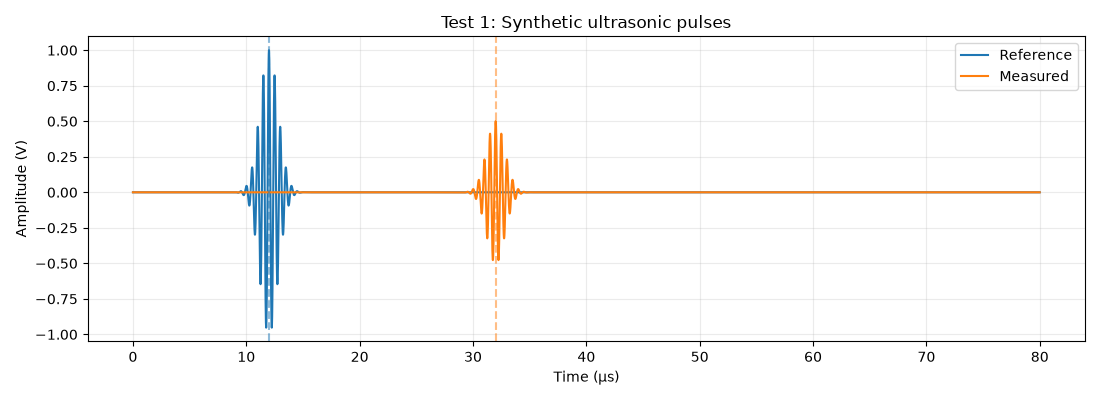


TEST 2: ATTENUATION VERIFICATION

Spectral attenuation
---------------------------------------------
Expected: 6.00000000 dB
Measured: 5.96160550 dB
Error:    -0.03839450 dB
Tolerance: ±0.10000000 dB
Result: PASS

TEST 3: GAIN CORRECTION VERIFICATION

Gain-corrected attenuation
---------------------------------------------
Expected: 6.00000000 dB
Measured: 5.96159587 dB
Error:    -0.03840413 dB
Tolerance: ±0.10000000 dB
Result: PASS

TEST 4: SIGNAL-TO-NOISE RATIO
SNR before filtering: 28.399 dB
SNR after filtering:  42.238 dB
SNR improvement: 13.839 dB
Result: PASS

TEST 5: REPEATABILITY VERIFICATION
Number of measurements: 30

Time of flight:
Known ToF: 20.000000 µs
Mean ToF:  20.000000 µs
SD:        0.000000 µs
u_A(mean): 0.000000 µs

Attenuation:
Known attenuation: 6.000000 dB
Mean attenuation:  6.053070 dB
SD:                0.227109 dB
u_A(mean):         0.041464 dB


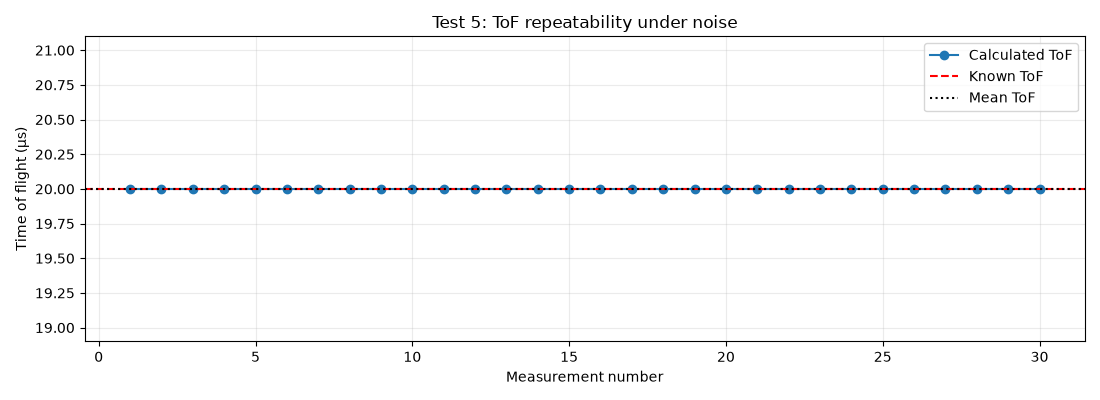


VERIFICATION SUMMARY
                      test  expected  measured  passed
            Time of flight      20.0 20.000000    True
      Spectral attenuation       6.0  5.961605    True
Gain-corrected attenuation       6.0  5.961596    True
           SNR improvement       0.0 13.838790    True

Passed: 4 of 4 checks


In [48]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# VERIFICATION CONFIGURATION
# ============================================================

FS = 100e6              # Sampling frequency: 100 MHz
FC = 2e6                # Carrier frequency: 2 MHz
DURATION = 80e-6        # Recording duration: 80 µs
SIGMA = 0.8e-6          # Gaussian envelope standard deviation

REF_CENTRE = 12e-6
KNOWN_TOF = 20e-6
REC_CENTRE = REF_CENTRE + KNOWN_TOF

KNOWN_ATTENUATION_DB = 6.0
AMPLITUDE_RATIO = 10 ** (-KNOWN_ATTENUATION_DB / 20)

N_REPEATS = 30
RNG = np.random.default_rng(42)

time = np.arange(
    int(round(DURATION * FS)),
    dtype=float
) / FS


# ============================================================
# SYNTHETIC ULTRASONIC SIGNAL
# ============================================================

def gaussian_pulse(time, centre, amplitude=1.0):
    """
    Gaussian-modulated sinusoidal pulse.

    y(t) = A exp(-(t-t0)^2 / (2 sigma^2))
           cos(2 pi fc (t-t0))
    """
    tau = time - centre

    envelope = np.exp(
        -(tau ** 2) / (2 * SIGMA ** 2)
    )

    carrier = np.cos(
        2 * np.pi * FC * tau
    )

    return amplitude * envelope * carrier


def generate_test_signals(
    tof=KNOWN_TOF,
    attenuation_db=KNOWN_ATTENUATION_DB,
    noise_std=0.0,
    measured_gain_db=0.0,
    rng=RNG,
):
    """
    Create synthetic reference and measured signals.

    The measured pulse is delayed and attenuated.

    An optional amplifier gain and Gaussian noise
    can be added to the measured signal.
    """

    reference = gaussian_pulse(
        time,
        REF_CENTRE,
        amplitude=1.0
    )

    attenuation_factor = 10 ** (
        -attenuation_db / 20
    )

    amplifier_factor = 10 ** (
        measured_gain_db / 20
    )

    measured = gaussian_pulse(
        time,
        REF_CENTRE + tof,
        amplitude=attenuation_factor * amplifier_factor
    )

    if noise_std > 0:
        reference = reference + rng.normal(
            0, noise_std, len(time)
        )

        measured = measured + rng.normal(
            0, noise_std, len(time)
        )

    return reference, measured


# ============================================================
# CALL THE EXISTING IMPLEMENTATION
# ============================================================

def run_framework(reference, measured, measured_gain_db=0.0):
    """
    Run the existing review_ultrasonic_signals()
    without modifying its implementation.
    """

    return review_ultrasonic_signals(
        time.copy(),
        reference.copy(),
        measured.copy(),
        cutoff_percentage=0.05,
        frequency_cutoff_expander=10,
        time_cutoff_expander=10,
        min_cutoff_frequency=0.0,
        ref_db_gain=0.0,

        # Existing function multiplies the signal
        # by 10^(measured_db_gain/20).
        # Therefore, negate applied amplifier gain.
        measured_db_gain=-measured_gain_db
    )


def report_test(name, measured_value, expected_value, unit, tolerance):
    error = measured_value - expected_value

    passed = abs(error) <= tolerance

    print(f"\n{name}")
    print("-" * 45)
    print(f"Expected: {expected_value:.8f} {unit}")
    print(f"Measured: {measured_value:.8f} {unit}")
    print(f"Error:    {error:.8f} {unit}")
    print(f"Tolerance: ±{tolerance:.8f} {unit}")
    print(f"Result: {'PASS' if passed else 'FAIL'}")

    return {
        "test": name,
        "expected": expected_value,
        "measured": measured_value,
        "error": error,
        "tolerance": tolerance,
        "passed": passed
    }


verification_results = []


# ============================================================
# TEST 1: TIME-OF-FLIGHT VERIFICATION
# ============================================================

print("\n" + "=" * 60)
print("TEST 1: TIME-OF-FLIGHT VERIFICATION")
print("=" * 60)

reference, measured = generate_test_signals(
    noise_std=1e-6
)

result = run_framework(reference, measured)

tof, attenuation = result[:2]

# Peak picking is sample-based.
# Use one sampling interval as the acceptance tolerance.
time_tolerance = 1 / FS

verification_results.append(
    report_test(
        "Time of flight",
        tof * 1e6,
        KNOWN_TOF * 1e6,
        "µs",
        time_tolerance * 1e6
    )
)

fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(time * 1e6, reference, label="Reference")
ax.plot(time * 1e6, measured, label="Measured")

ax.axvline(
    REF_CENTRE * 1e6,
    linestyle="--",
    color="C0",
    alpha=0.5
)

ax.axvline(
    REC_CENTRE * 1e6,
    linestyle="--",
    color="C1",
    alpha=0.5
)

ax.set_title("Test 1: Synthetic ultrasonic pulses")
ax.set_xlabel("Time (µs)")
ax.set_ylabel("Amplitude (V)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


# ============================================================
# TEST 2: ATTENUATION VERIFICATION
# ============================================================

print("\n" + "=" * 60)
print("TEST 2: ATTENUATION VERIFICATION")
print("=" * 60)

# The attenuation is known analytically:
#
# attenuation = -20 log10(A_measured / A_reference)
#
# Here it should equal 6 dB.

verification_results.append(
    report_test(
        "Spectral attenuation",
        attenuation,
        KNOWN_ATTENUATION_DB,
        "dB",
        tolerance=0.1
    )
)


# ============================================================
# TEST 3: GAIN CORRECTION VERIFICATION
# ============================================================

print("\n" + "=" * 60)
print("TEST 3: GAIN CORRECTION VERIFICATION")
print("=" * 60)

APPLIED_GAIN_DB = 12.0

reference_gain, measured_gain = generate_test_signals(
    attenuation_db=KNOWN_ATTENUATION_DB,
    measured_gain_db=APPLIED_GAIN_DB,
    noise_std=1e-6
)

gain_result = run_framework(
    reference_gain,
    measured_gain,
    measured_gain_db=APPLIED_GAIN_DB
)

gain_corrected_attenuation = gain_result[1]

verification_results.append(
    report_test(
        "Gain-corrected attenuation",
        gain_corrected_attenuation,
        KNOWN_ATTENUATION_DB,
        "dB",
        tolerance=0.1
    )
)


# ============================================================
# TEST 4: SIGNAL-TO-NOISE RATIO
# ============================================================

print("\n" + "=" * 60)
print("TEST 4: SIGNAL-TO-NOISE RATIO")
print("=" * 60)

reference_noise, measured_noise = generate_test_signals(
    noise_std=0.02
)

noise_result = run_framework(
    reference_noise,
    measured_noise
)

snr_before = noise_result[7]
snr_after = noise_result[8]

print(f"SNR before filtering: {snr_before:.3f} dB")
print(f"SNR after filtering:  {snr_after:.3f} dB")

snr_improvement = snr_after - snr_before

print(f"SNR improvement: {snr_improvement:.3f} dB")

snr_passed = snr_improvement > 0

print(
    f"Result: {'PASS' if snr_passed else 'FAIL'}"
)

verification_results.append({
    "test": "SNR improvement",
    "expected": 0.0,
    "measured": snr_improvement,
    "error": snr_improvement,
    "tolerance": np.nan,
    "passed": snr_passed
})


# ============================================================
# TEST 5: REPEATED MEASUREMENTS
# ============================================================

print("\n" + "=" * 60)
print("TEST 5: REPEATABILITY VERIFICATION")
print("=" * 60)

tofs = []
attenuations = []

for i in range(N_REPEATS):

    reference_i, measured_i = generate_test_signals(
        noise_std=0.02
    )

    result_i = run_framework(
        reference_i,
        measured_i
    )

    tofs.append(result_i[0])
    attenuations.append(result_i[1])

tofs = np.asarray(tofs)
attenuations = np.asarray(attenuations)

# Sample statistics
mean_tof = np.mean(tofs)
std_tof = np.std(tofs, ddof=1)
u_mean_tof = std_tof / np.sqrt(N_REPEATS)

mean_attenuation = np.mean(attenuations)
std_attenuation = np.std(attenuations, ddof=1)
u_mean_attenuation = (
    std_attenuation / np.sqrt(N_REPEATS)
)

print(f"Number of measurements: {N_REPEATS}")

print("\nTime of flight:")
print(f"Known ToF: {KNOWN_TOF * 1e6:.6f} µs")
print(f"Mean ToF:  {mean_tof * 1e6:.6f} µs")
print(f"SD:        {std_tof * 1e6:.6f} µs")
print(f"u_A(mean): {u_mean_tof * 1e6:.6f} µs")

print("\nAttenuation:")
print(f"Known attenuation: {KNOWN_ATTENUATION_DB:.6f} dB")
print(f"Mean attenuation:  {mean_attenuation:.6f} dB")
print(f"SD:                {std_attenuation:.6f} dB")
print(f"u_A(mean):         {u_mean_attenuation:.6f} dB")

# Plot individual measurements
fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(
    np.arange(1, N_REPEATS + 1),
    tofs * 1e6,
    "o-",
    label="Calculated ToF"
)

ax.axhline(
    KNOWN_TOF * 1e6,
    linestyle="--",
    color="red",
    label="Known ToF"
)

ax.axhline(
    mean_tof * 1e6,
    linestyle=":",
    color="black",
    label="Mean ToF"
)

ax.set_title("Test 5: ToF repeatability under noise")
ax.set_xlabel("Measurement number")
ax.set_ylabel("Time of flight (µs)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


# ============================================================
# VERIFICATION SUMMARY
# ============================================================

verification_df = pd.DataFrame(verification_results)

print("\n" + "=" * 60)
print("VERIFICATION SUMMARY")
print("=" * 60)

print(
    verification_df[
        ["test", "expected", "measured", "passed"]
    ].to_string(index=False)
)

print(
    f"\nPassed: {verification_df['passed'].sum()} "
    f"of {len(verification_df)} checks"
)

verification_df.to_csv(
    "python_framework_verification.csv",
    index=False
)


In [55]:
# Run in Jupyter (uncomment if needed):
# %pip install ipympl
%matplotlib widget

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from IPython.display import display, clear_output
from ipywidgets import Button, Output, HBox

# IMPORTANT: First run/import the module containing your existing functions:
# from your_module import get_frequency_spectra_range, get_ultrasonic_characteristics

CSV_PATH = r"C:\Users\januv\Downloads\Tests 11_02\Calibrated\dir 1 40 by 40_waveforms.csv"
N_TO_REVIEW = 30
RANDOM_SEED = 2026
SNAP_RADIUS_US = 0.30  # Click within this distance of the desired positive peak
FREQ_CUTOFF_PERCENTAGE = 0.05
FREQ_CUTOFF_EXPANDER = 10
MIN_CUTOFF_FREQUENCY = 0.0
RESULTS_PATH = "manual_tof_verification.csv"

required = {"acquisition", "sample", "time_s", "filtered_reference_v", "filtered_measured_v"}
df = pd.read_csv(CSV_PATH)
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing CSV columns: {sorted(missing)}")

acquisitions = np.array(sorted(df["acquisition"].dropna().unique()))
if len(acquisitions) < N_TO_REVIEW:
    raise ValueError(f"Only {len(acquisitions)} acquisitions found; need {N_TO_REVIEW}.")
selected = np.random.default_rng(RANDOM_SEED).choice(acquisitions, N_TO_REVIEW, replace=False)
print("Selected acquisitions:", selected.tolist())

Selected acquisitions: [13, 21, 25, 14, 8, 30, 29, 3, 28, 15, 6, 1, 11, 27, 20, 22, 2, 10, 17, 5, 23, 7, 4, 9, 26, 12, 18, 24, 19, 16]


In [56]:
def automatic_tof(t, ref, measured):
    if "get_frequency_spectra_range" not in globals() or "get_ultrasonic_characteristics" not in globals():
        raise NameError("Import your existing get_frequency_spectra_range and get_ultrasonic_characteristics functions first.")
    fmin, fmax, dt = get_frequency_spectra_range(
        t, ref, FREQ_CUTOFF_PERCENTAGE, FREQ_CUTOFF_EXPANDER, MIN_CUTOFF_FREQUENCY
    )
    tof, attenuation_db = get_ultrasonic_characteristics(t, ref, measured, fmin, fmax, dt)
    return float(tof), float(attenuation_db)

records = []
for acq in selected:
    g = df.loc[df["acquisition"] == acq].sort_values("sample")
    t = g["time_s"].to_numpy(dtype=float)
    ref = g["filtered_reference_v"].to_numpy(dtype=float)
    meas = g["filtered_measured_v"].to_numpy(dtype=float)
    if not (np.all(np.isfinite(t)) and np.all(np.isfinite(ref)) and np.all(np.isfinite(meas))):
        raise ValueError(f"Acquisition {acq}: nonfinite values")
    if len(t) < 3 or np.any(np.diff(t) <= 0):
        raise ValueError(f"Acquisition {acq}: invalid time axis")
    auto, att = automatic_tof(t, ref, meas)
    records.append({"acquisition": acq, "time": t, "reference": ref, "measured": meas,
                    "auto_tof_s": auto, "attenuation_db": att, "manual_ref_idx": None,
                    "manual_meas_idx": None})
print(f"Prepared {len(records)} acquisitions for review.")

Prepared 30 acquisitions for review.


In [ ]:

class ManualToFReviewer:
    def __init__(self, records, snap_radius_us=0.30):
        self.records = records
        self.snap_radius_s = snap_radius_us * 1e-6
        self.position = 0
        self.clicks = []

        self.output = Output()
        self.undo = Button(description="Undo click")
        self.save = Button(
            description="Save & next",
            button_style="success"
        )

        self.undo.on_click(self.on_undo)
        self.save.on_click(self.on_save)

        display(HBox([self.undo, self.save]), self.output)
        self.show_current()

    def show_current(self):
        if self.position >= len(self.records):
            with self.output:
                clear_output(wait=True)
                print(
                    "All acquisitions reviewed. "
                    "Run the export cell below."
                )
            return

        self.clicks = []
        r = self.records[self.position]

        t = r["time"]
        ref = r["reference"]
        meas = r["measured"]

        with self.output:
            clear_output(wait=True)

            print(
                f"Acquisition {r['acquisition']} "
                f"({self.position + 1}/{len(self.records)})"
            )
            print(
                "Click a positive REFERENCE peak on the upper plot, "
                "then the corresponding positive MEASURED peak "
                "on the lower plot."
            )
            print(
                "Automatic ToF:",
                f"{r['auto_tof_s'] * 1e6:.6f} µs"
            )

            # Two vertically stacked axes
            self.fig, (self.ax_ref, self.ax_meas) = plt.subplots(
                2, 1,
                figsize=(12, 7),
                sharex=True,
                gridspec_kw={"hspace": 0.15}
            )

            # Reference signal (upper axis)
            self.ax_ref.plot(
                t * 1e6,
                ref,
                label="Reference",
                color="C0"
            )

            self.ax_ref.axvline(
                t[np.argmax(ref)] * 1e6,
                color="C0",
                ls=":",
                alpha=0.65,
                label="Auto reference maximum"
            )

            self.ax_ref.set(
                ylabel="Voltage (V)",
                title=(
                    f"Manual ToF verification — "
                    f"acquisition {r['acquisition']}"
                )
            )
            self.ax_ref.grid(alpha=0.2)
            self.ax_ref.legend(loc="upper right")

            # Measured signal (lower axis)
            self.ax_meas.plot(
                t * 1e6,
                meas,
                label="Measured",
                color="C1"
            )

            self.ax_meas.axvline(
                t[np.argmax(meas)] * 1e6,
                color="C1",
                ls=":",
                alpha=0.65,
                label="Auto measured maximum"
            )

            self.ax_meas.set(
                xlabel="Time (µs)",
                ylabel="Voltage (V)"
            )
            self.ax_meas.grid(alpha=0.2)
            self.ax_meas.legend(loc="upper right")

            self.fig.canvas.mpl_connect(
                "button_press_event",
                self.on_click
            )
            self.cid = self.fig.canvas.mpl_connect(
                "button_press_event",
                self.on_click
            )

            plt.show()

    def on_click(self, event):
        if self.position >= len(self.records):
            return

        if event.xdata is None:
            return

        if len(self.clicks) >= 2:
            return

        which = len(self.clicks)

        # First click must be on reference axis.
        # Second click must be on measured axis.
        expected_ax = (
            self.ax_ref if which == 0 else self.ax_meas
        )

        if event.inaxes != expected_ax:
            print(
                "Please click on the "
                + ("REFERENCE" if which == 0 else "MEASURED")
                + " axis."
            )
            return

        r = self.records[self.position]
        t = r["time"]

        y = (
            r["reference"]
            if which == 0
            else r["measured"]
        )

        peaks, _ = find_peaks(y)
        peaks = peaks[y[peaks] > 0]

        if not len(peaks):
            print("No positive local maxima found.")
            return

        click_t = event.xdata * 1e-6

        nearest = peaks[
            np.argmin(np.abs(t[peaks] - click_t))
        ]

        if abs(t[nearest] - click_t) > self.snap_radius_s:
            print(
                "Click was too far from a positive peak. "
                "Zoom in or increase SNAP_RADIUS_US."
            )
            return

        self.clicks.append(int(nearest))

        color = "C0" if which == 0 else "C1"

        expected_ax.scatter(
            t[nearest] * 1e6,
            y[nearest],
            s=110,
            marker="o",
            facecolor="none",
            edgecolor=color,
            linewidth=2,
            zorder=10
        )

        expected_ax.annotate(
            (
                "Manual ref"
                if which == 0
                else "Manual measured"
            ),
            (t[nearest] * 1e6, y[nearest]),
            xytext=(5, 12),
            textcoords="offset points",
            color=color
        )

        self.fig.canvas.draw_idle()

        print(
            f"Selected "
            f"{'reference' if which == 0 else 'measured'} "
            f"peak: {t[nearest] * 1e6:.6f} µs"
        )

        if len(self.clicks) == 2:
            manual = (
                t[self.clicks[1]]
                - t[self.clicks[0]]
            )

            print(
                f"Manual ToF: {manual * 1e6:.6f} µs; "
                f"difference from auto: "
                f"{(r['auto_tof_s'] - manual) * 1e6:.6f} µs"
            )

    def on_undo(self, _):
        if self.position >= len(self.records):
            return

        if not self.clicks:
            return

        self.clicks.pop()

        # Preserve remaining selections
        previous = self.clicks.copy()

        self.fig.canvas.mpl_disconnect(self.cid)
        plt.close(self.fig)

        self.show_current()

        for i, idx in enumerate(previous):
            r = self.records[self.position]

            y = (
                r["reference"]
                if i == 0
                else r["measured"]
            )

            ax = (
                self.ax_ref
                if i == 0
                else self.ax_meas
            )

            self.clicks.append(idx)

            ax.scatter(
                r["time"][idx] * 1e6,
                y[idx],
                s=110,
                facecolor="none",
                edgecolor=f"C{i}",
                linewidth=2,
                zorder=10
            )

        self.fig.canvas.draw_idle()

    def on_save(self, _):
        if self.position >= len(self.records):
            return

        if len(self.clicks) != 2:
            print("Select both peaks before saving.")
            return

        r = self.records[self.position]

        manual = (
            r["time"][self.clicks[1]]
            - r["time"][self.clicks[0]]
        )

        if manual <= 0:
            print(
                "Measured peak must occur after "
                "reference peak. Use Undo to correct."
            )
            return

        r["manual_ref_idx"], r["manual_meas_idx"] = self.clicks

        self.fig.canvas.mpl_disconnect(self.cid)
        plt.close(self.fig)

        self.position += 1
        self.show_current()


reviewer = ManualToFReviewer(
    records,
    snap_radius_us=SNAP_RADIUS_US
)


Output()

,acquisition,auto_reference_peak_time_us,auto_measured_peak_time_us,manual_reference_peak_time_us,manual_measured_peak_time_us,auto_tof_us,manual_tof_us,difference_us,absolute_difference_us
0,13,5.733333,25.800000,7.600000,27.733333,20.066667,20.133333,-0.066667,0.066667
1,21,5.533333,25.600000,3.666667,23.666667,20.066667,20.000000,0.066667,0.066667
2,25,5.666667,25.800000,2.000000,22.000000,20.133333,20.000000,0.133333,0.133333
3,14,5.733333,25.800000,7.533333,27.733333,20.066667,20.200000,-0.133333,0.133333
4,8,5.600000,25.733333,1.933333,21.933333,20.133333,20.000000,0.133333,0.133333
5,30,5.533333,25.600000,3.666667,23.666667,20.066667,20.000000,0.066667,0.066667
6,29,5.600000,25.666667,3.733333,23.800000,20.066667,20.066667,0.000000,0.000000
7,3,5.600000,25.666667,1.866667,21.933333,20.066667,20.066667,-0.000000,0.000000
8,28,5.666667,25.733333,3.800000,23.800000,20.066667,20.000000,0.066667,0.066667
9,15,5.600000,25.733333,3.733333,23.800000,20.133333,20.066667,0.066667,0.066667


Mean signed difference (µs): 0.026666666666665846
Mean absolute difference (µs): 0.05333333333332616
Maximum absolute difference (µs): 0.13333333333330044
Exact sample-level agreement: 10 of 30
Saved: manual_tof_verification.csv


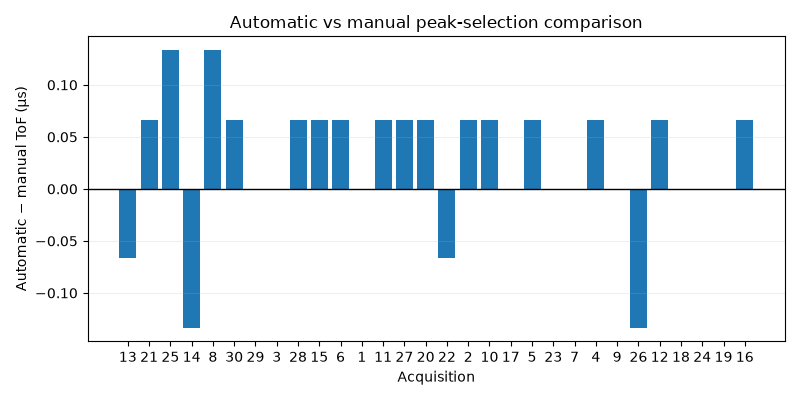

In [58]:
if any(r["manual_ref_idx"] is None or r["manual_meas_idx"] is None for r in records):
    raise RuntimeError("Complete all five manual selections before exporting.")

rows = []
for r in records:
    t, ref, meas = r["time"], r["reference"], r["measured"]
    manual_ref_t = t[r["manual_ref_idx"]]
    manual_meas_t = t[r["manual_meas_idx"]]
    manual_tof = manual_meas_t - manual_ref_t
    auto_ref_t = t[np.argmax(ref)]
    auto_meas_t = t[np.argmax(meas)]
    rows.append({
        "acquisition": r["acquisition"],
        "auto_reference_peak_time_us": auto_ref_t * 1e6,
        "auto_measured_peak_time_us": auto_meas_t * 1e6,
        "manual_reference_peak_time_us": manual_ref_t * 1e6,
        "manual_measured_peak_time_us": manual_meas_t * 1e6,
        "auto_tof_us": r["auto_tof_s"] * 1e6,
        "manual_tof_us": manual_tof * 1e6,
        "difference_us": (r["auto_tof_s"] - manual_tof) * 1e6,
        "absolute_difference_us": abs(r["auto_tof_s"] - manual_tof) * 1e6,
    })

comparison = pd.DataFrame(rows)
display(comparison.round(6))
print("Mean signed difference (µs):", comparison["difference_us"].mean())
print("Mean absolute difference (µs):", comparison["absolute_difference_us"].mean())
print("Maximum absolute difference (µs):", comparison["absolute_difference_us"].max())
print("Exact sample-level agreement:", int(np.sum(np.isclose(comparison["difference_us"], 0, atol=1e-8))),
      "of", len(comparison))
comparison.to_csv(RESULTS_PATH, index=False)
print("Saved:", RESULTS_PATH)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(comparison["acquisition"].astype(str), comparison["difference_us"])
ax.axhline(0, color="black", linewidth=1)
ax.set(xlabel="Acquisition", ylabel="Automatic − manual ToF (µs)",
       title="Automatic vs manual peak-selection comparison")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()